# <center> **MATH&ML-10. Кластеризация и техники понижения размерности. Часть I**

>**Кластеризация** — это задача группировки объектов на подмножества (кластеры) таким образом, чтобы объекты из одного кластера были более похожи друг на друга, чем на объекты из других кластеров, по какому-либо критерию.

# <center> **2. K-Means**

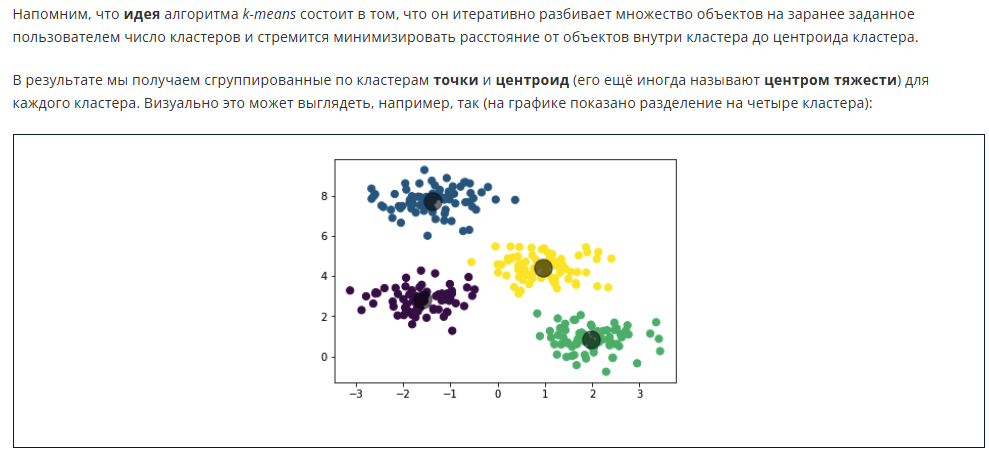

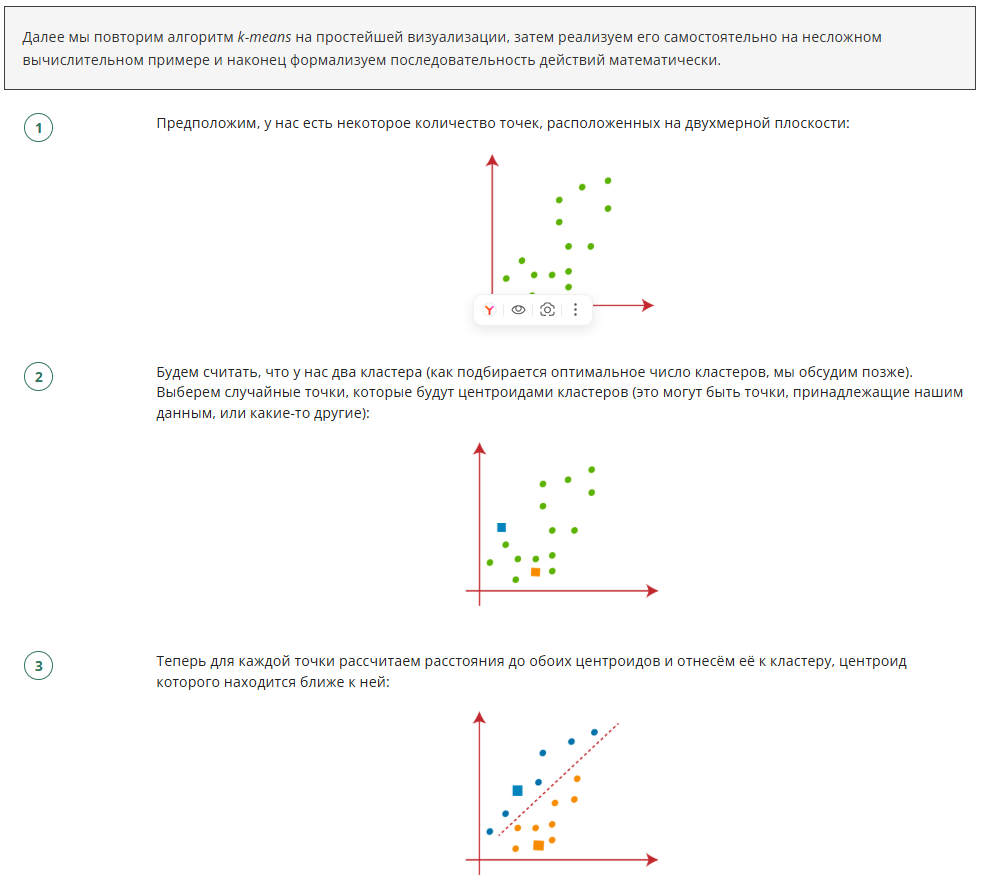

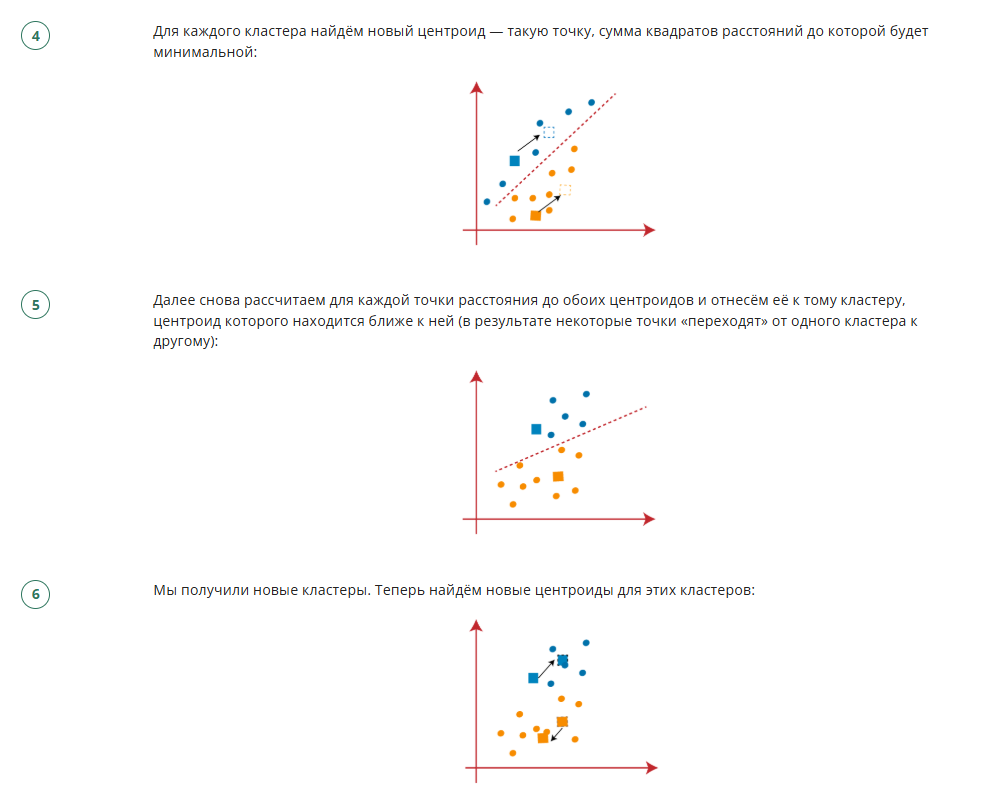

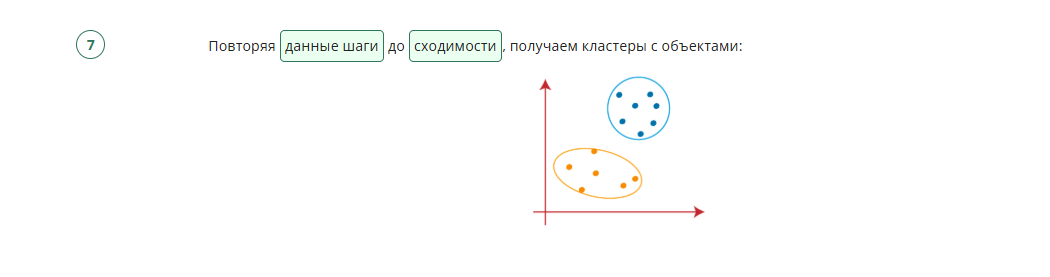

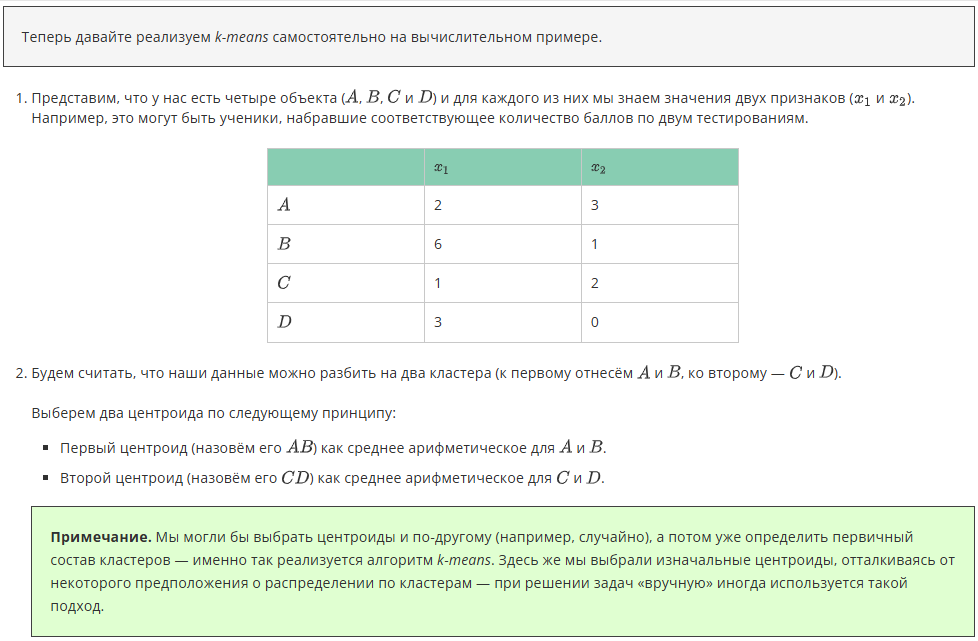

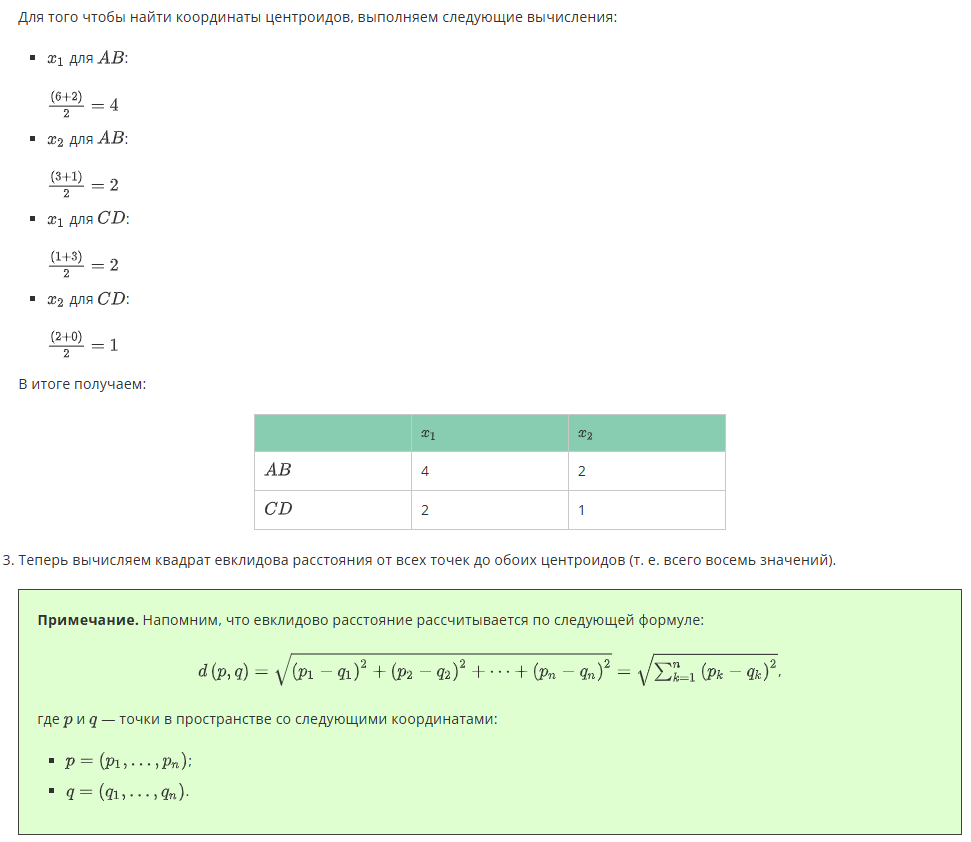

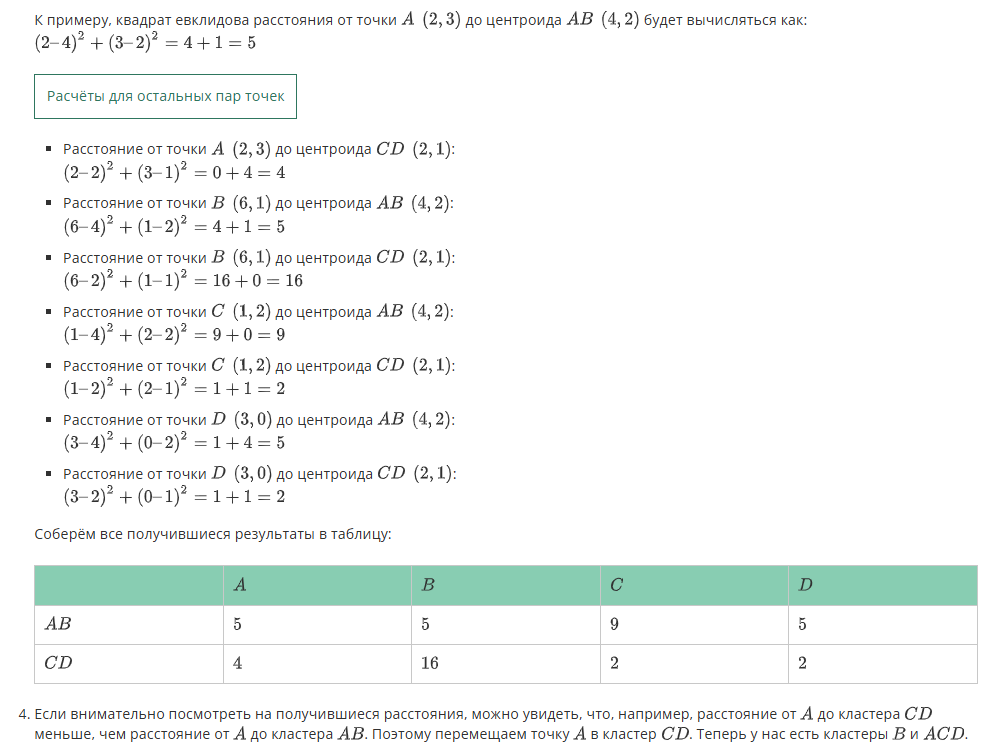

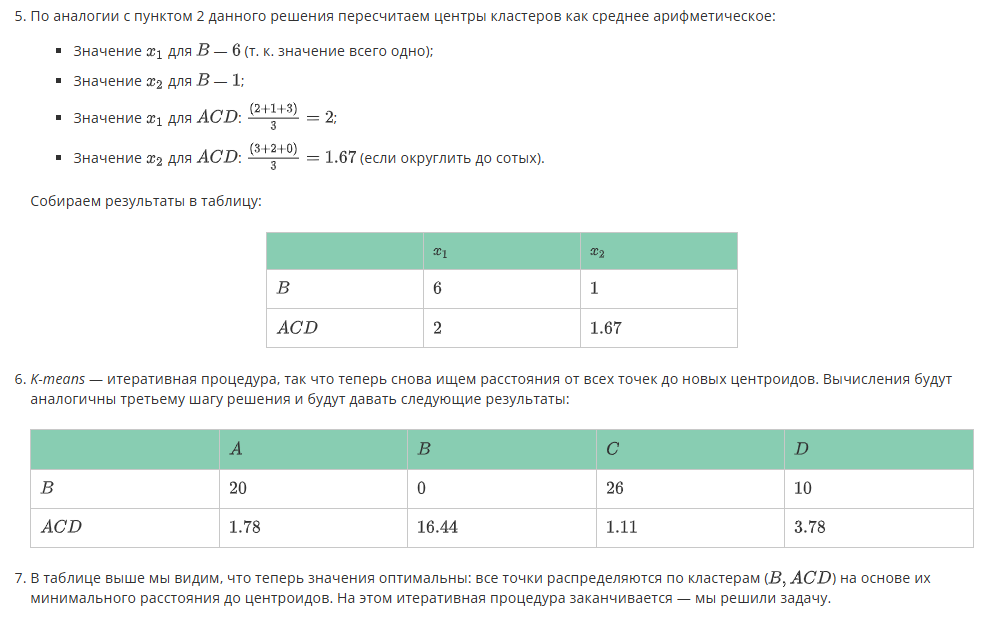

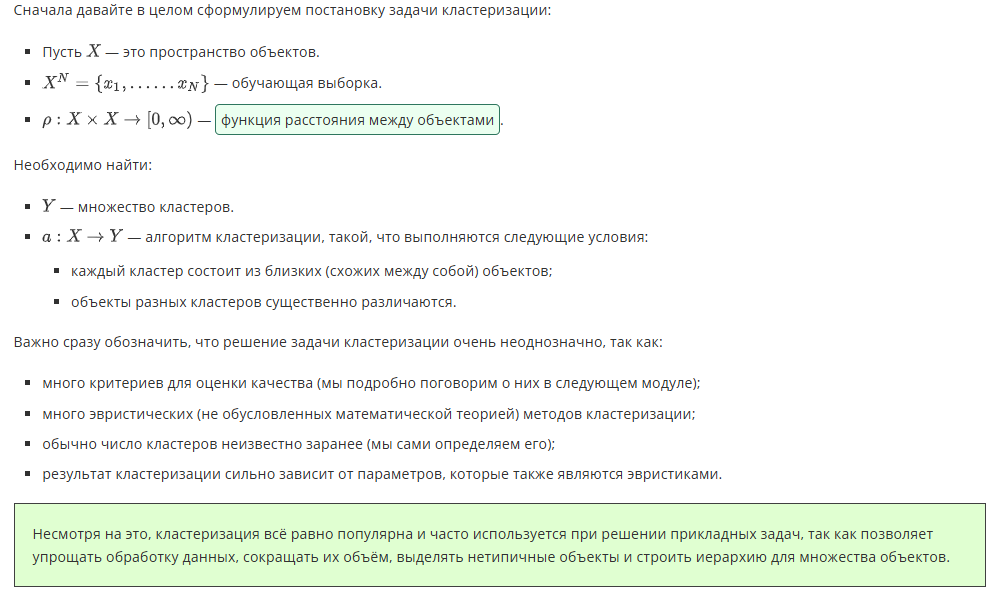

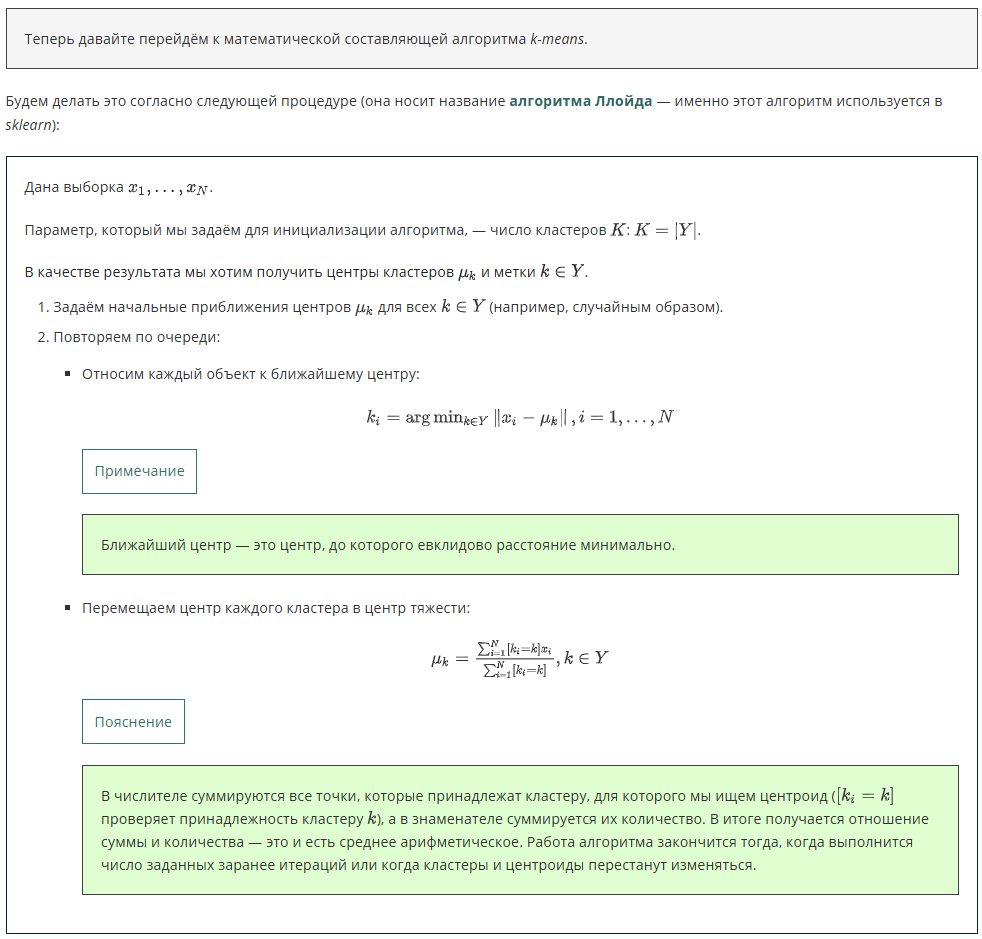

Для того чтобы запустить алгоритм кластеризации k-means, нам нужна библиотека sklearn и модуль [KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html).

Что необходимо для запуска?
* Задать количество кластеров, на которые необходимо разделить данные.
* Данные, т. е. параметры объектов (), которые мы будем передавать в виде матрицы наблюдений X.

Пример

* ```n_clusters``` — количество кластеров;
* ```n_init``` — количество итераций алгоритма k-means;
* ```random_state``` — параметр для воспроизводимости результатов от запуска к запуску.

In [5]:
from sklearn.cluster import KMeans
# инициализируем алгоритм k-means с количеством кластеров 3
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)

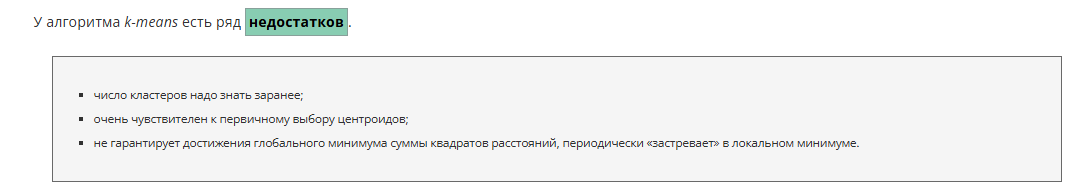

##   <center> Mini-Batch K-means

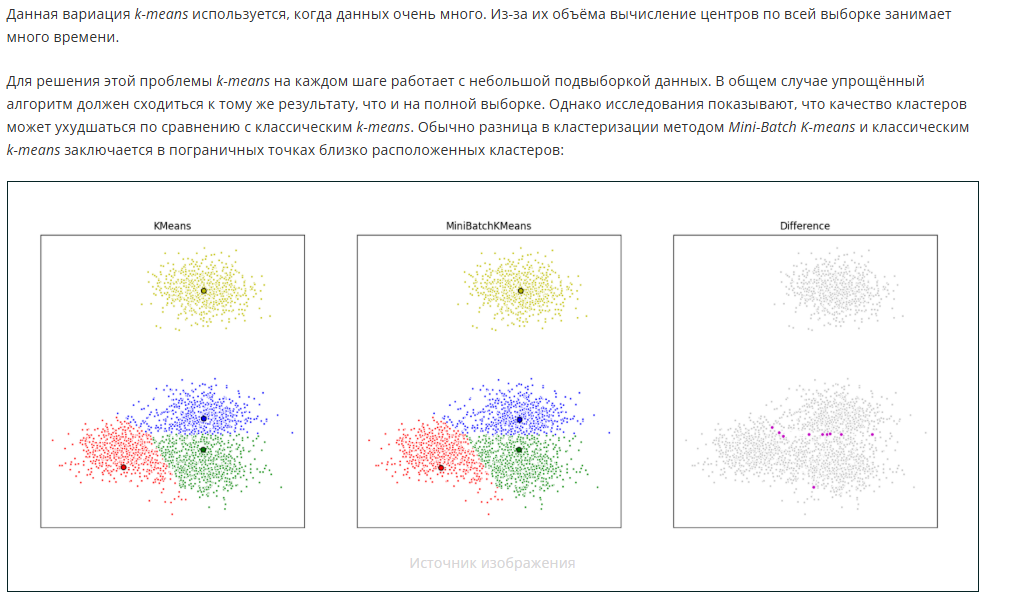

Для того чтобы запустить алгоритм кластеризации Mini-Batch K-means, нам нужна библиотека sklearn и модуль [MiniBatchKMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.MiniBatchKMeans.html). Его применение и параметры аналогичны классическому Kmeans. Отличие лишь в том, что можно дополнительно настроить объём подвыборки:

In [6]:
from sklearn.cluster import MiniBatchKMeans
# два кластера и подвыборки объёма 6
kmeans = MiniBatchKMeans(n_clusters=2,random_state=42,batch_size=6)

## <center> K-means++

Данную вариацию *k-means* используют, если признаков очень много.

Результат и время работы алгоритма зависят от изначального выбора центроидов. Чтобы минимизировать затраты, будем действовать следующим образом:
1. Первый центроид выбираем случайным образом.
2. Для каждой точки вычисляем квадрат расстояния до ближайшего центроида из тех, что уже поставлены.
3. Далее из этих точек выбираем следующий центроид так, чтобы вероятность выбора точки была пропорциональна вычисленному для неё квадрату расстояния.
4. Когда все точки выбраны, реализуем k-means.

По умолчанию при запуске *k-means* в *sklearn* используется именно алгоритм *k-means++*. Выбор алгоритма задаётся через параметр ```init```:
* ```init='random'``` — для классической версии k-means;
* ```init='k-means++'``` — для вариации k-means++.

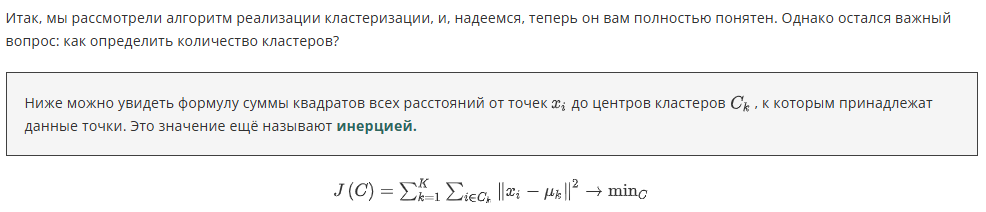

При реализации алгоритма *k-means* для получения значения инерции используется атрибут ```inertia_```. Например, в одном из предыдущих модулей мы создавали функцию, чтобы находить значения инерции для разного количества кластеров:

In [7]:
def get_inertia(cluster_num, X):
# инициализируем алгоритм кластеризации
    k_means =  KMeans(n_clusters=cluster_num, random_state=42)
# запускаем алгоритм k-means
    k_means.fit(X)
# находим значение инерции
    inertia = k_means.inertia_
# возвращаем значение инерции
    return inertia

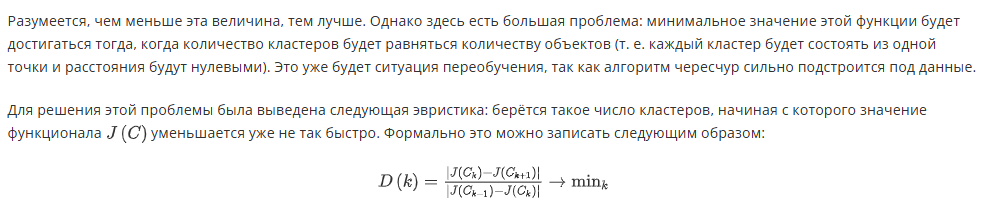

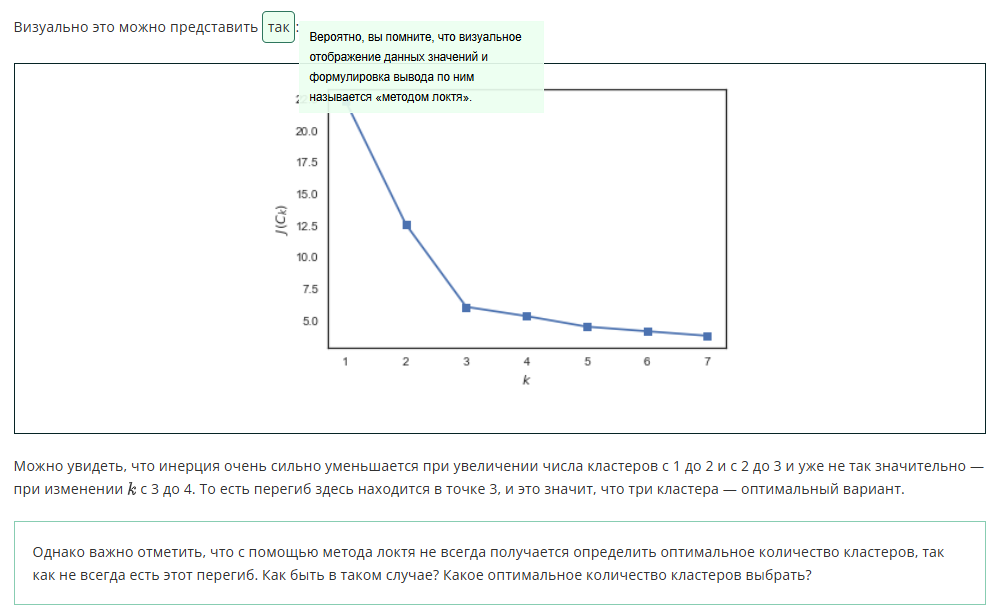

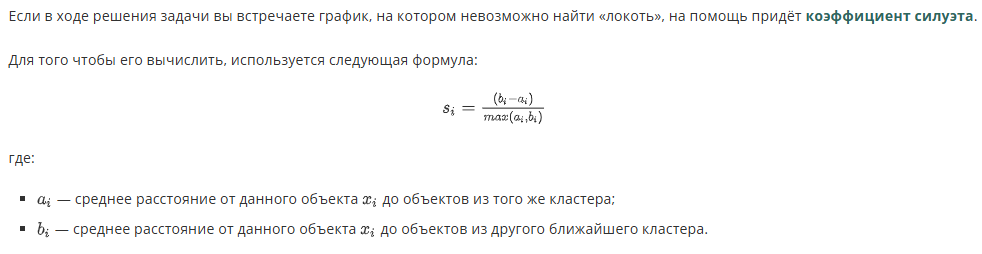

Для вычисления коэффициента силуэта используется [silhouette_score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html). Вспомним функцию из предыдущего модуля по кластеризации, которую мы использовали для расчёта значений коэффициента силуэта для разного количества кластеров:

In [8]:
from sklearn.metrics import silhouette_score
def get_silhouette(cluster_num, X):
    k_means =  KMeans(n_clusters=cluster_num, random_state=42)
    k_means.fit(X)
# подсчитаем метрику силуэта, передав данные и то, к каким кластерам относятся объекты
    silhouette = silhouette_score(X, k_means.labels_)
    return silhouette

silhouette = []
for clust_num in range(2, 10):
    silhouette.append(get_silhouette(clust_num, X))

NameError: name 'X' is not defined

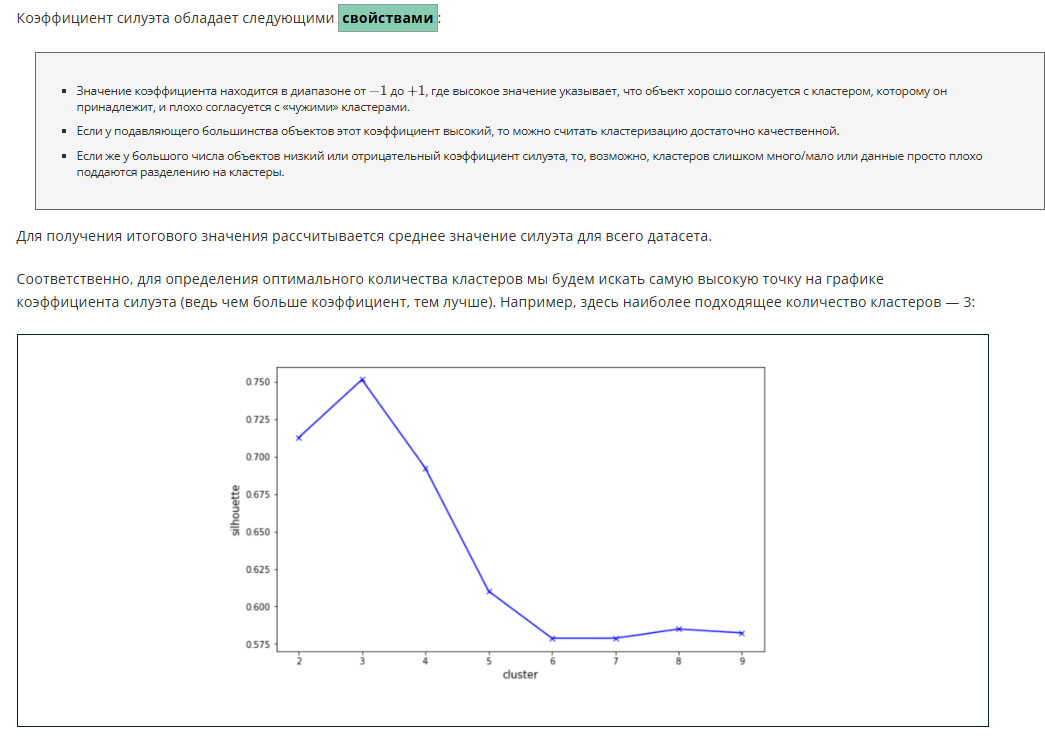

---

# <center> **3. EM-алгоритм**

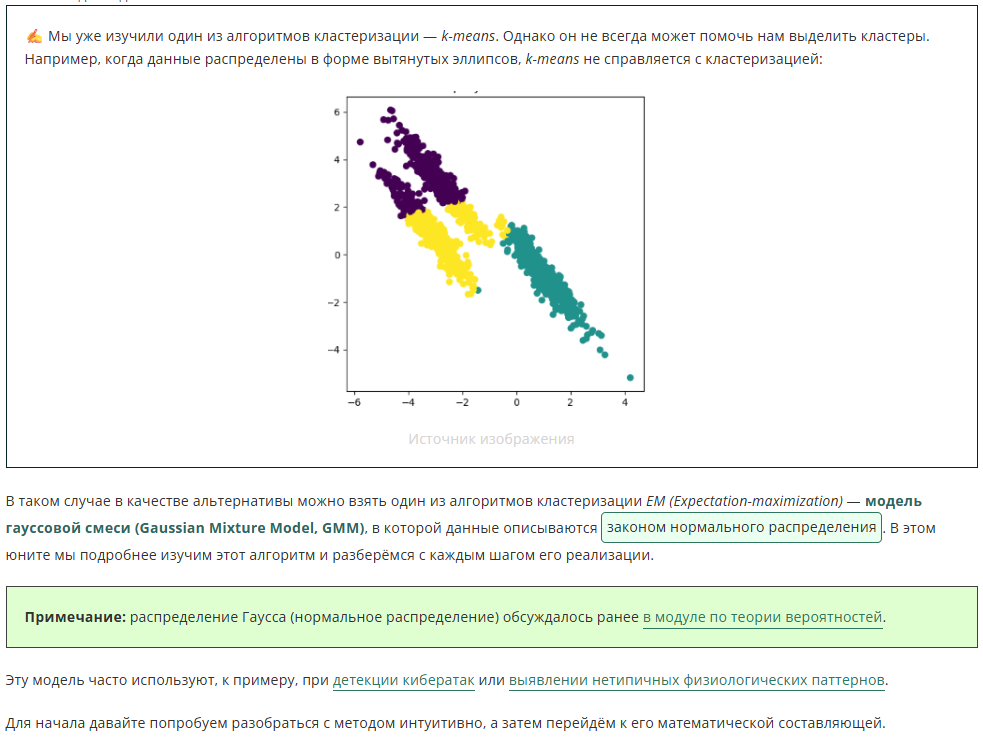

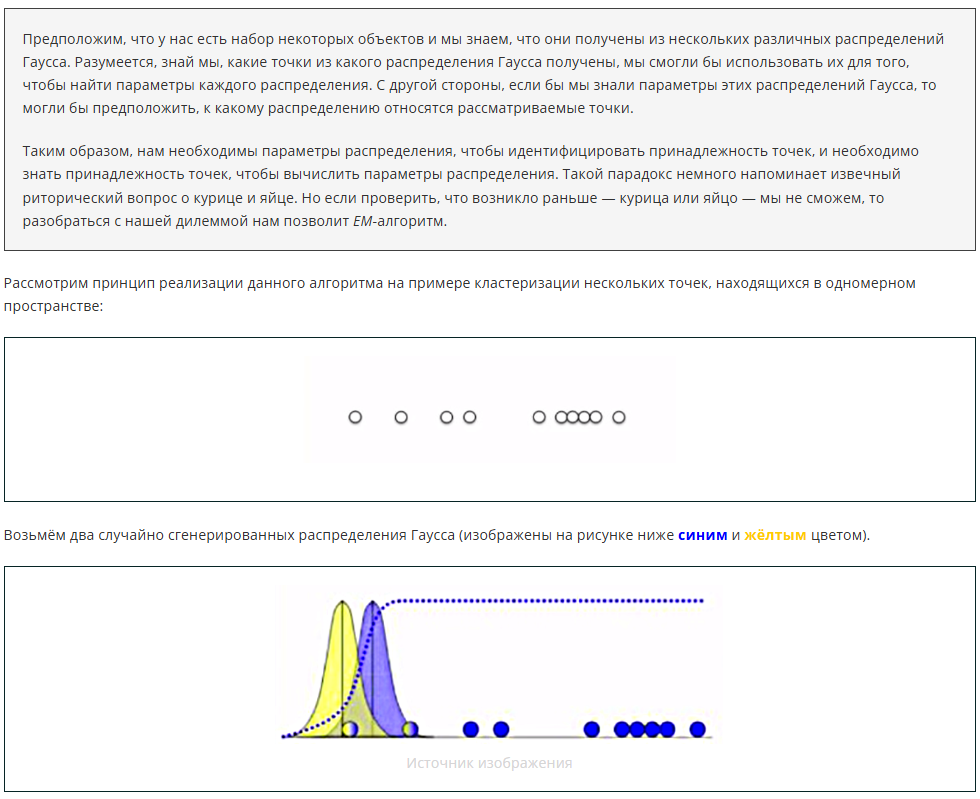

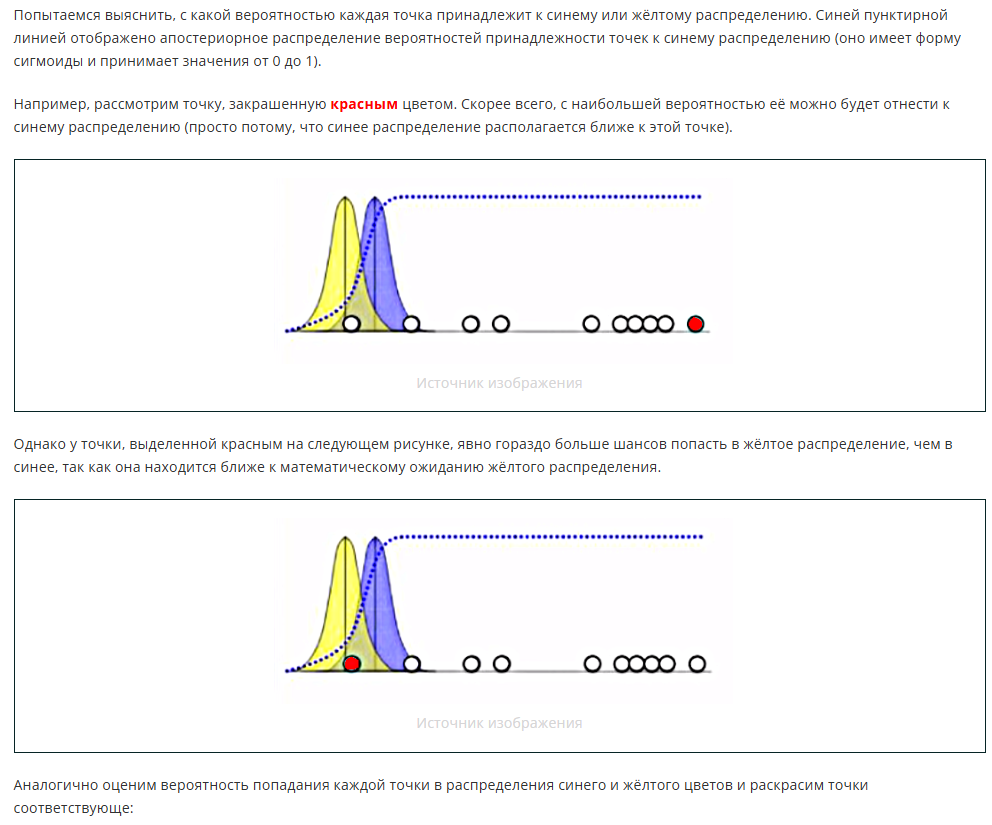

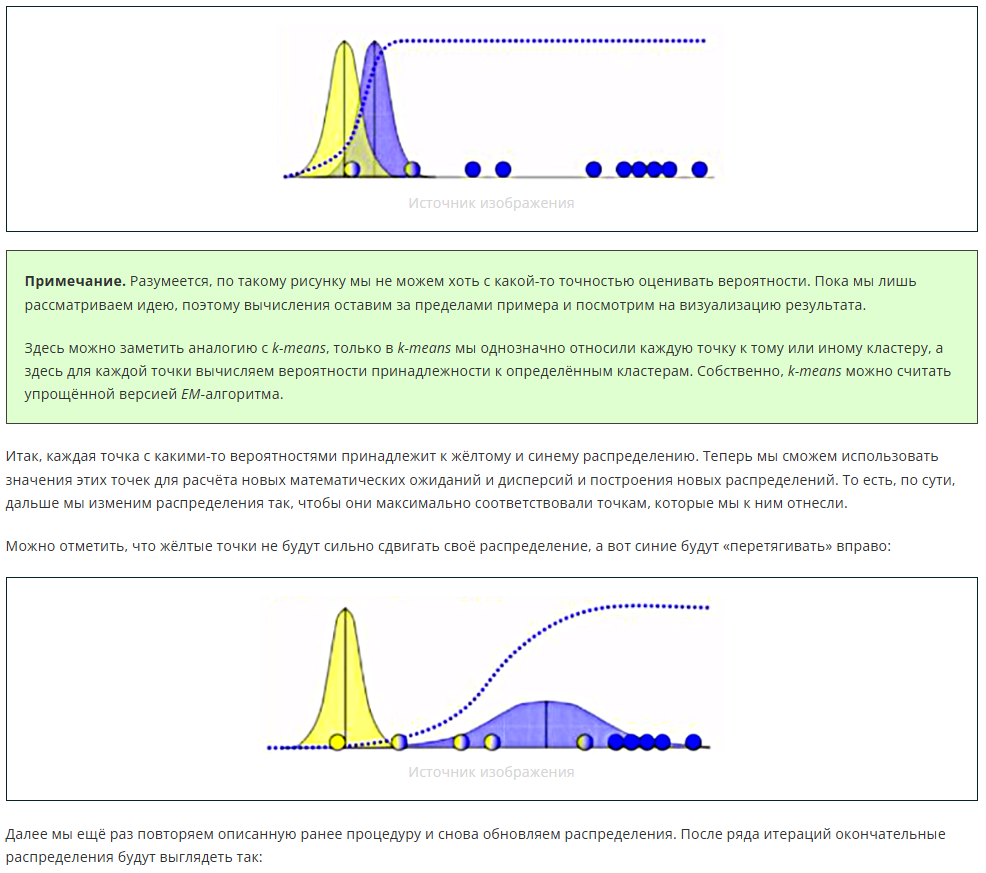

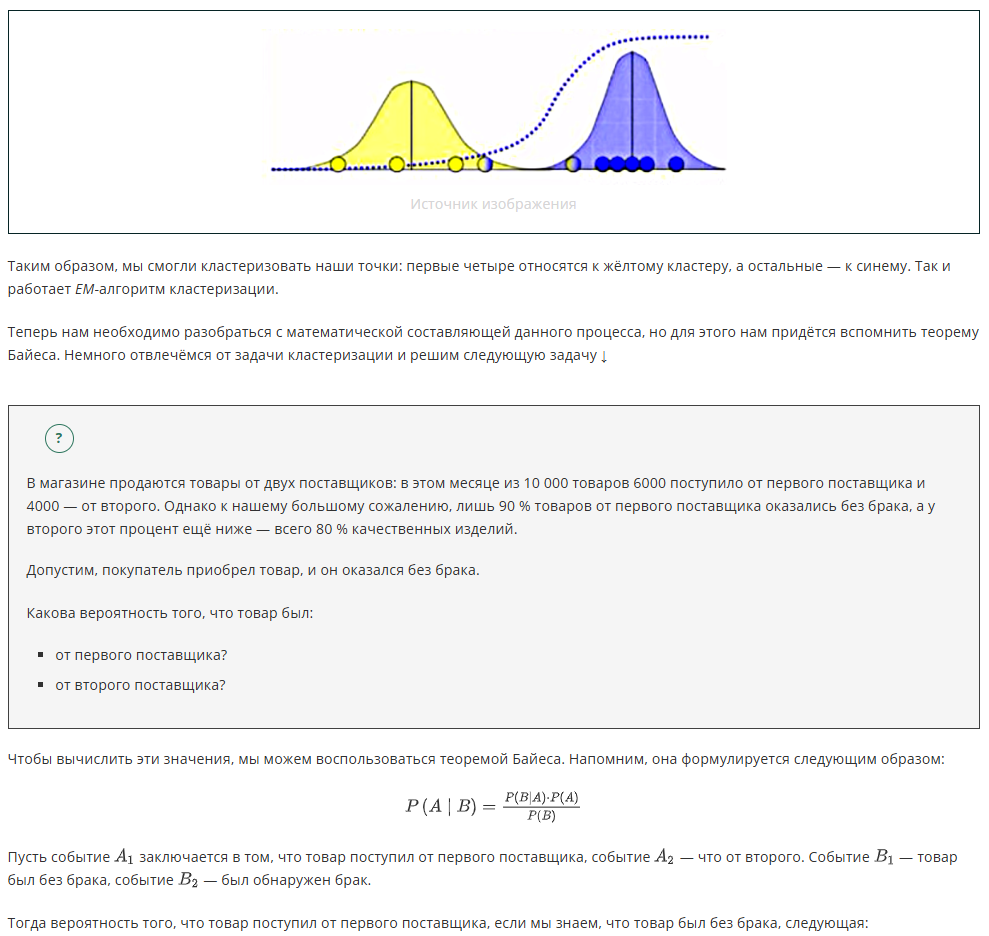

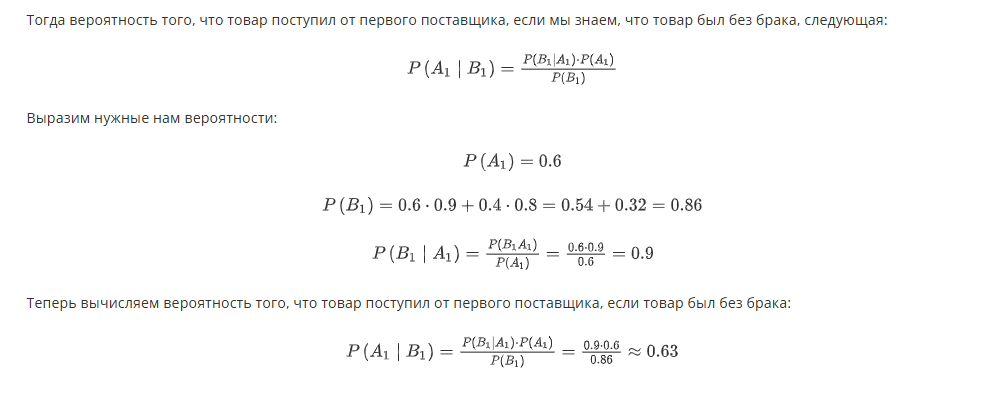

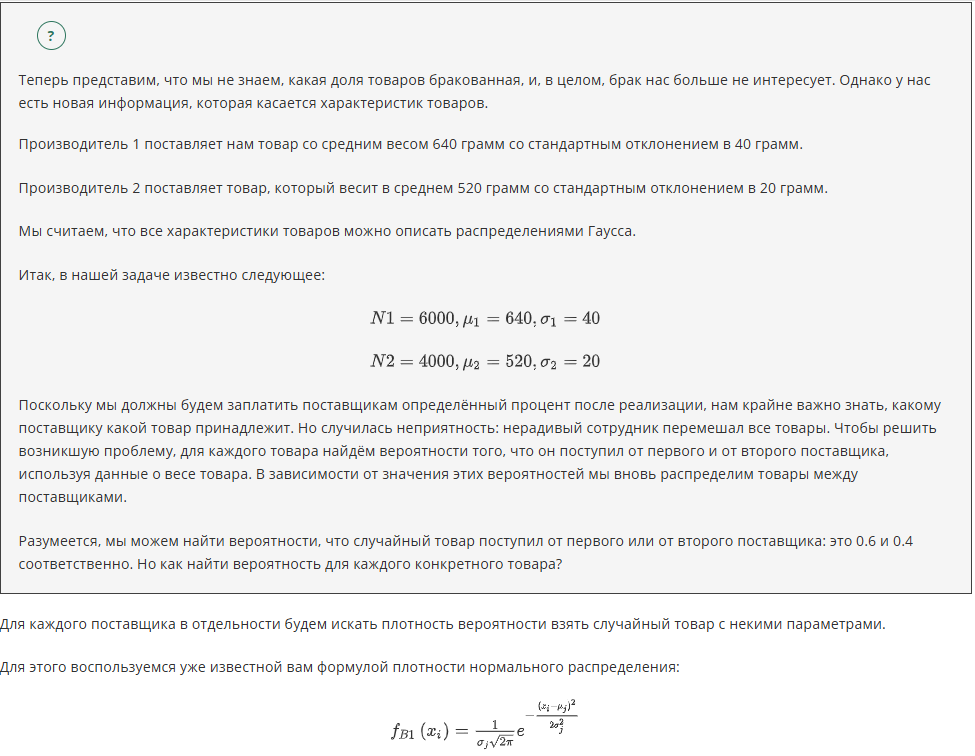

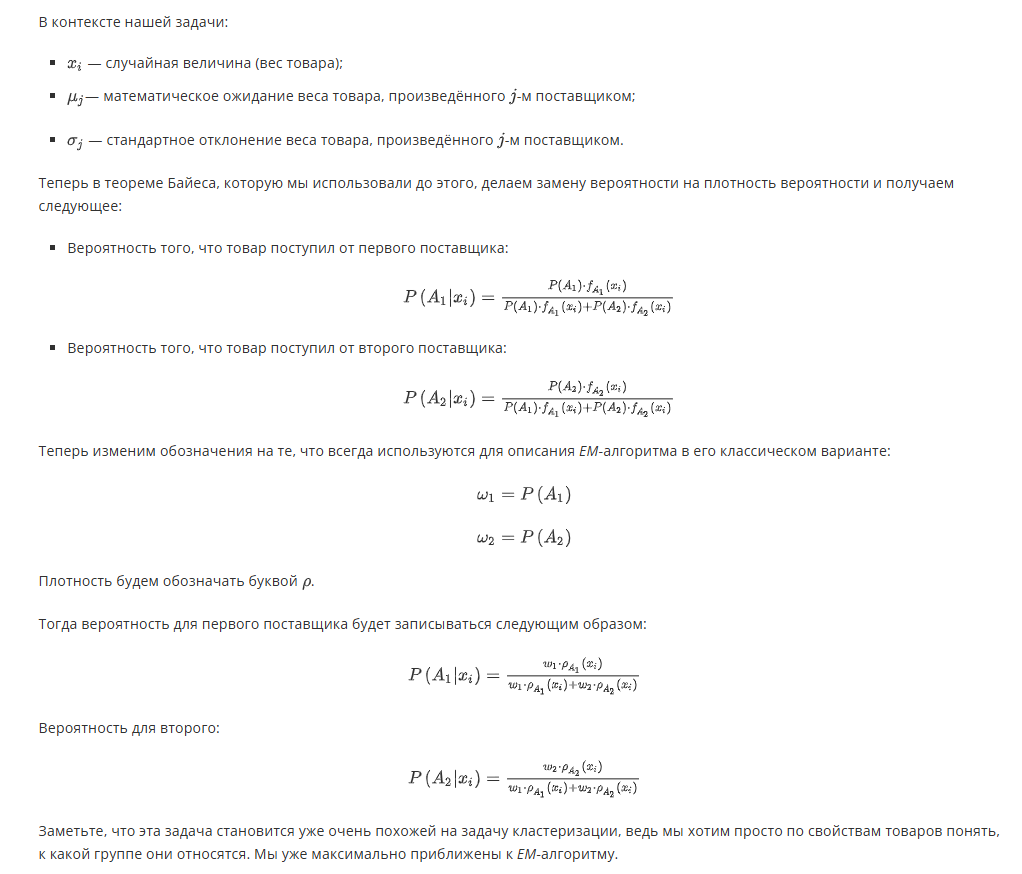

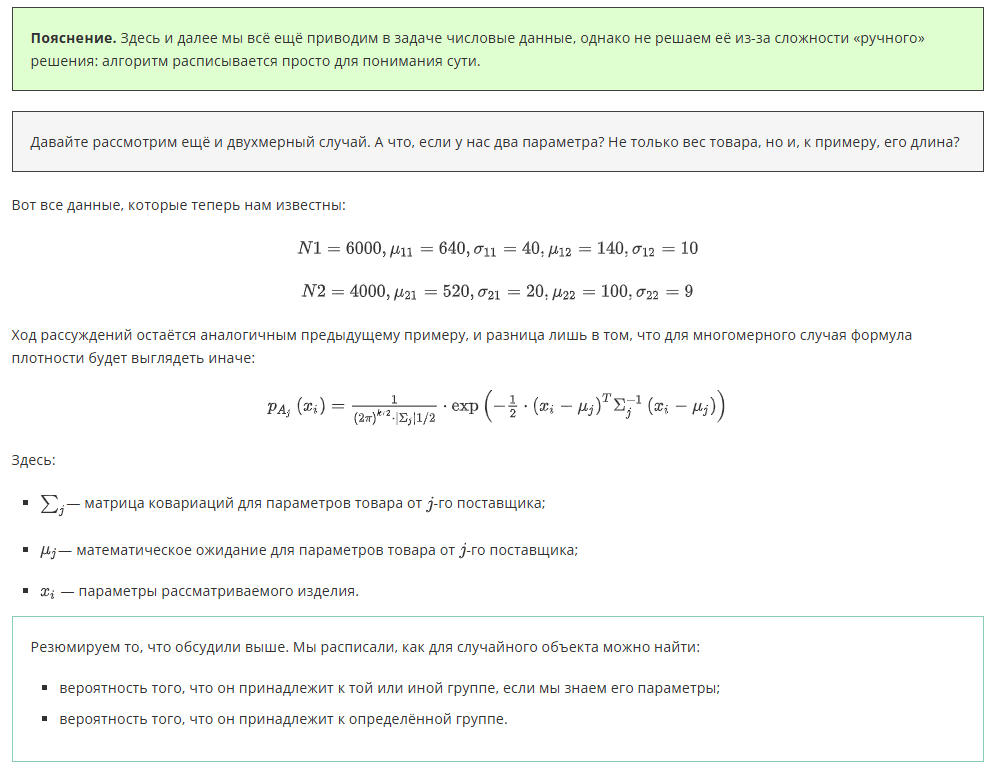

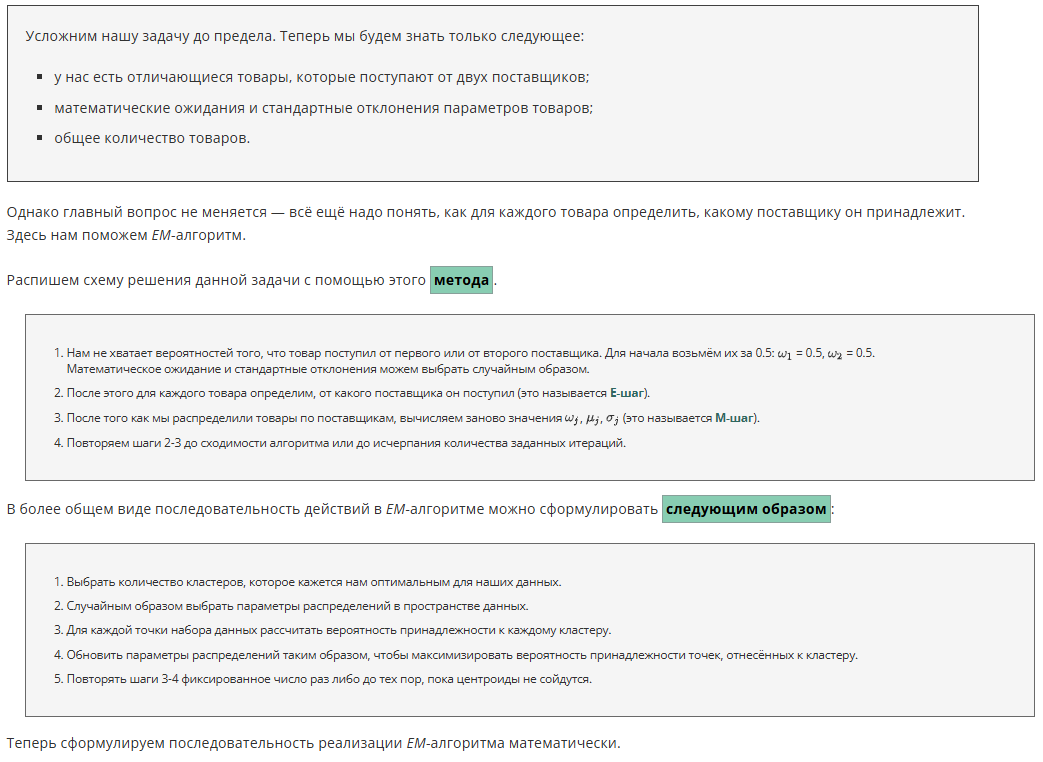

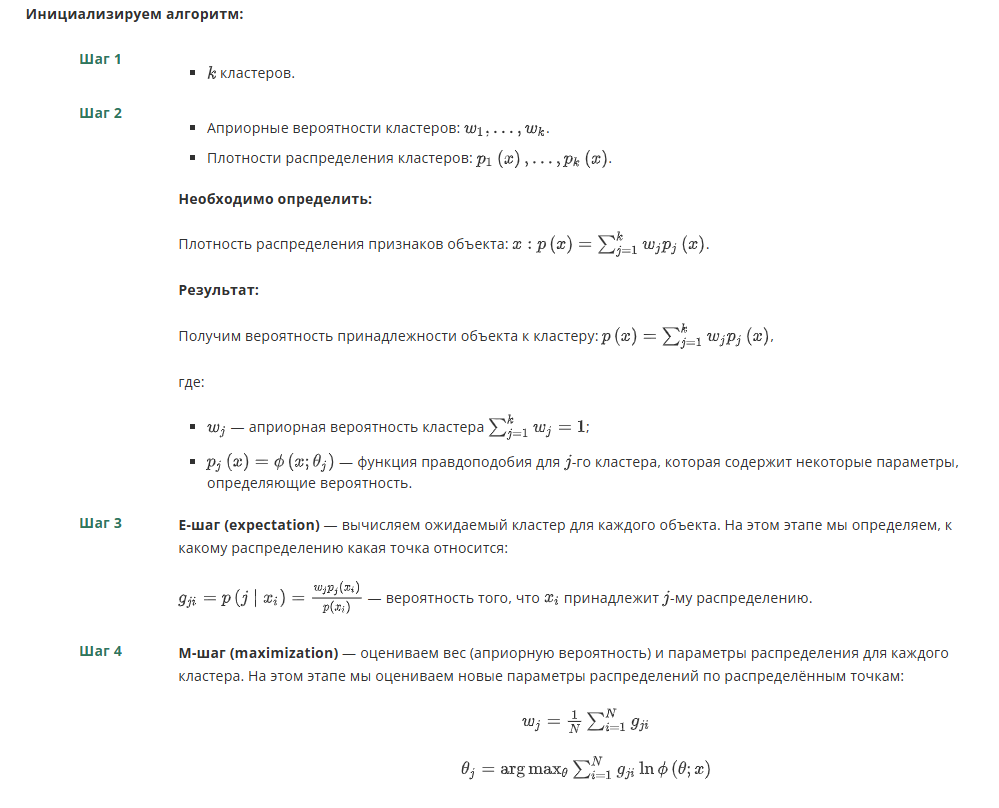

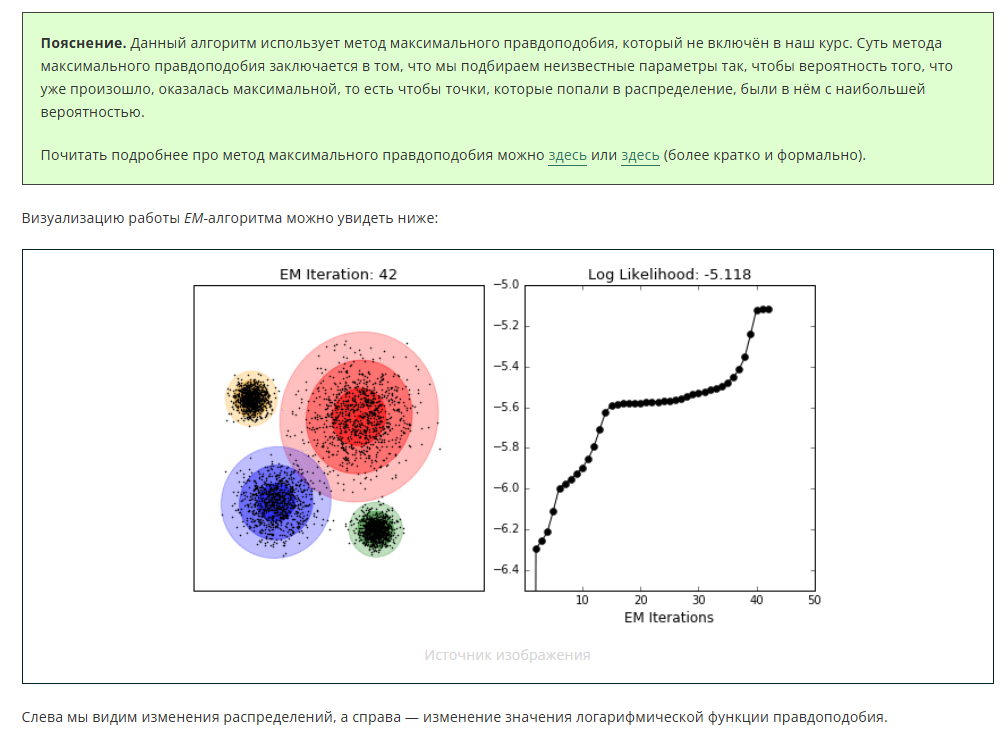

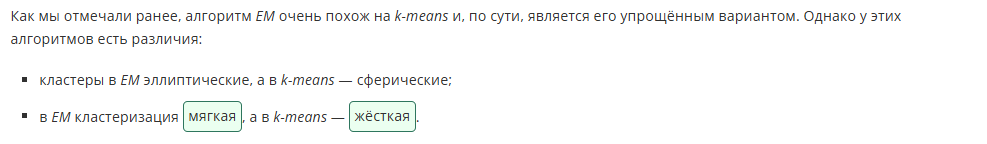

Для реализации алгоритма в *sklearn* мы используем [GaussianMixture](https://scikit-learn.org/stable/modules/generated/sklearn.mixture.GaussianMixture.html). Для запуска алгоритма *GaussianMixture* необходимо задать следующие основные параметры:
* n_components — количество кластеров;
* random_state — так как в алгоритме есть случайность при инициализации, то для воспроизводимости результатов от запуска к запуску следует передать какое-то число.

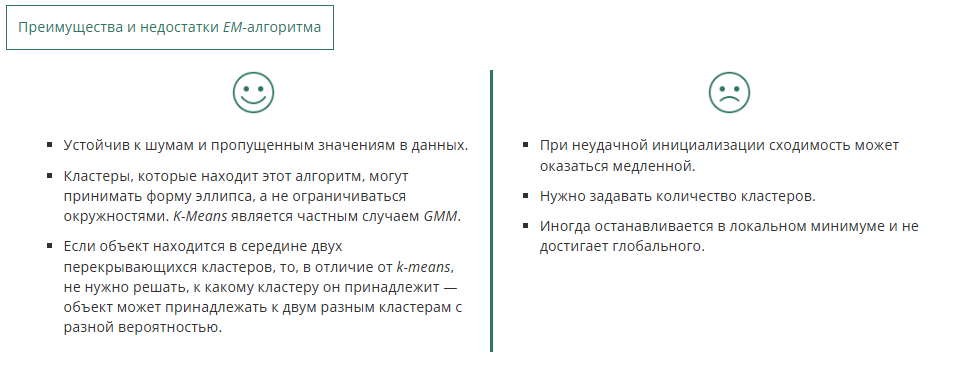

---

## <center> 4. K-Means и EM-алгоритм: практика

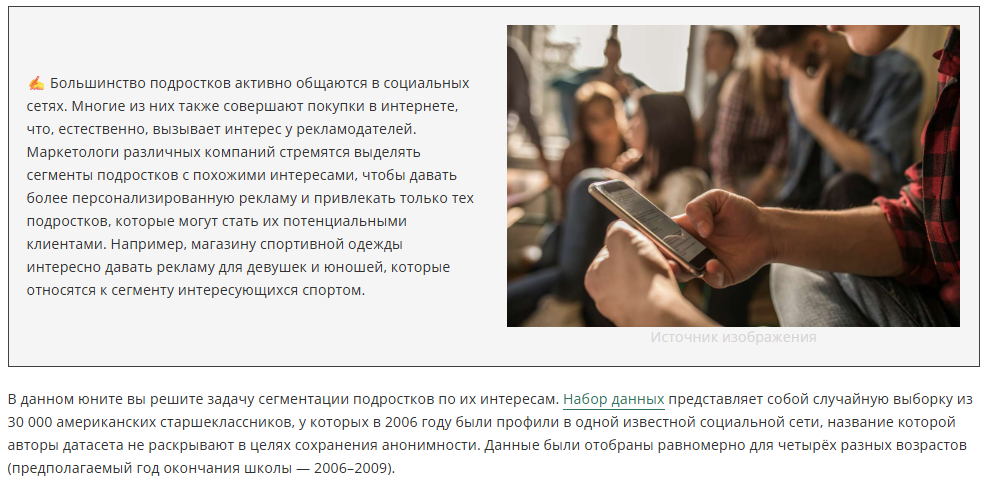

In [ ]:
import pandas as pd
df = pd.read_csv('data/snsdata.csv')
df.head()

,gradyear,gender,age,friends,basketball,football,soccer,softball,volleyball,swimming,...,blonde,mall,shopping,clothes,hollister,abercrombie,die,death,drunk,drugs
0,2006,M,18.982,7,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2006,F,18.801,0,0,1,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
2,2006,M,18.335,69,0,1,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
3,2006,F,18.875,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2006,NaN,18.995,10,0,0,0,0,0,0,...,0,0,2,0,0,0,0,0,1,1


Признаки в данных
* gradyear — год выпуска;
* gender — пол;
* age — возраст;
* friends — число друзей в социальной сети;
* basketball, football, soccer, softball, volleyball, swimming, cheerleading, baseball, tennis, sports, cute, sex, sexy, hot, kissed, dance, band, marching, music, rock, god, church, jesus, bible, hair, dress, blonde, mall, shopping, clothes, hollister, abercrombie, die, death, drunk, drugs (переменные с пятой по сороковую) — частота встречаемости соответствующих слов в сообщениях подростка.

In [ ]:
columns_to_drop = df.columns[0:4]
df = df.drop(columns=columns_to_drop,axis=1)
df.head()

,basketball,football,soccer,softball,volleyball,swimming,cheerleading,baseball,tennis,sports,...,blonde,mall,shopping,clothes,hollister,abercrombie,die,death,drunk,drugs
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,1,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
2,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,2,0,0,0,0,0,1,1


In [ ]:
df.shape

(30000, 36)

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_norm = scaler.fit_transform(df)
print(round(X_norm[0][0],2))

-0.33


In [ ]:
from sklearn.cluster import KMeans
def get_inertia(cluster_num, X):
# инициализируем алгоритм кластеризации
    k_means =  KMeans(n_clusters=cluster_num, random_state=42)
# запускаем алгоритм k-means
    k_means.fit(X)
# находим значение инерции
    inertia = k_means.inertia_
# возвращаем значение инерции
    return inertia
print(round(get_inertia(9, X_norm),2))

c:\Users\PC\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


857169.1


In [ ]:
# 1. Создаём и обучаем модель (именно её сохраняем в переменную)
k_means_model = KMeans(n_clusters=9, random_state=42)
k_means_model.fit(X_norm)

# 2. Теперь можно брать labels_
labels = k_means_model.labels_

import numpy as np
counts = np.bincount(labels)
max_cluster_size = counts.max()
min_cluster_size = counts.min()
print("Размер самого многочисленного кластера:", max_cluster_size)
print("Размер самого многочисленного кластера:", min_cluster_size)

c:\Users\PC\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


Размер самого многочисленного кластера: 19659
Размер самого многочисленного кластера: 1


c:\Users\PC\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
c:\Users\PC\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
c:\Users\PC\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
c:\Users\PC\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` 

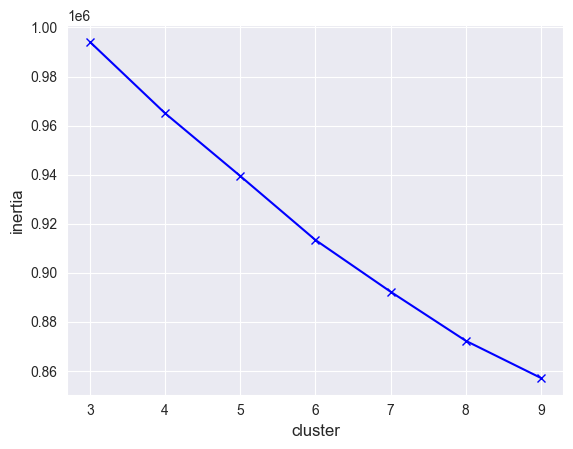

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans

# функция, которая принимает количество кластеров для k-means и матрицу с признаками объектов и возвращает инерцию 
def get_inertia(cluster_num, X):
# инициализируем алгоритм кластеризации
    k_means =  KMeans(n_clusters=cluster_num, random_state=42)
# запускаем алгоритм k-means
    k_means.fit(X)
# находим значение инерции
    inertia = k_means.inertia_
# возвращаем значение инерции
    return inertia

# создаём пустой список для значений инерции
inertia = []
# итерируемся по разным размерам кластеров (от 1 до 9) и сохраняем значение инерции для каждого кластера
for cluster_num in range(3, 10):
# сохраняем значения
    inertia.append(get_inertia(cluster_num, X_norm))

# визуализируем, как менялась инерция в зависимости от количества кластеров
# задаём названия осям x и y
plt.xlabel("cluster", fontsize=12)
plt.ylabel("inertia", fontsize=12)
# рисуем изменение инерции
plt.plot([i for i in range(3, 10)], inertia, 'xb-')

<Axes: xlabel='cluster', ylabel='silhouette'>

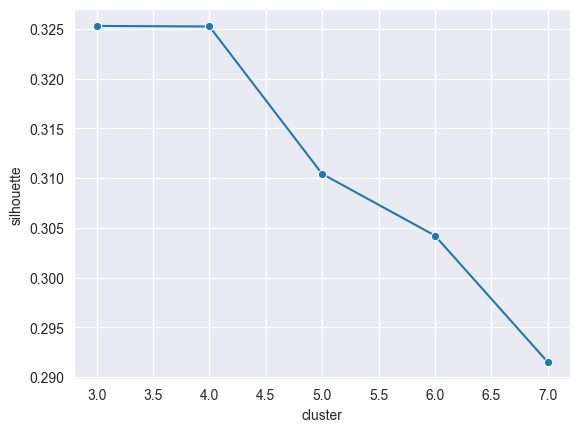

In [ ]:
# импортируем метрику силуэта
from sklearn.metrics import silhouette_score
import seaborn as sns
# напишем функцию, как и при подсчете метода локтя
def get_silhouette(cluster_num, X):
    k_means =  KMeans(n_clusters=cluster_num, init='k-means++', n_init=10, random_state=42)
    k_means.fit(X)
# подсчитаем метрику силуэта, передав данные и то, к каким кластерам относятся объекты
    silhouette = silhouette_score(X, k_means.predict(X))
    return silhouette

# создадим пустой словарь, ключами будут инерция и количество кластеров
silhouette_res = {"silhouette": [], "cluster": []}

# выберем нужные данные 
X = X_norm

for cluster_num in range(3, 8):
    silhouette_res["silhouette"].append(get_silhouette(cluster_num, X))
    silhouette_res["cluster"].append(cluster_num)
    
# сохраним в датафрейм значение силуэта и количество кластеров
silhouette_df = pd.DataFrame(silhouette_res)

# установим стиль для визуализиции
sns.set_style("darkgrid")
# визуализируем зависимость значения инерции от количества кластеров
sns.lineplot(data=silhouette_df, x="cluster", y="silhouette", marker= "o")

In [ ]:
from sklearn.cluster import KMeans
# 2. Кластеризуем: 3 кластера, фиксируем n_init и random_state
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
cluster_labels = kmeans.fit_predict(X_norm)

# Добавляем метки кластеров обратно в DataFrame
df['cluster'] = cluster_labels

# 3. Для каждого кластера считаем среднее по каждому признаку (слову)
# и выбираем топ‑10 признаков с наибольшим средним
top_words_per_cluster = {}

for c in range(3):
    # Берём строки только этого кластера
    cluster_data = df[df['cluster'] == c][df.columns]
    
    # Считаем среднее по каждому слову (признаку)
    mean_values = cluster_data.mean()
    
    # Сортируем по убыванию и берём топ‑10
    top_10 = mean_values.sort_values(ascending=False).head(10)
    
    # Сохраняем как список слов (названия колонок)
    top_words_per_cluster[c] = top_10.index.tolist()

print("Топ‑10 слов для каждого кластера:")
for c, words in top_words_per_cluster.items():
    print(f"Кластер {c}: {words}")

# 4. Находим слова, которые встречаются в топ‑10 каждого кластера
# (то есть общие ключевые слова для всех трёх)
sets = [set(words) for words in top_words_per_cluster.values()]
common_words = sets[0].intersection(*sets[1:])

print("\nСлова, характерные для всех кластеров (пересечение топ‑10):")
print(sorted(common_words))

Топ‑10 слов для каждого кластера:
Кластер 0: ['music', 'dance', 'shopping', 'god', 'cute', 'hair', 'church', 'basketball', 'mall', 'football']
Кластер 1: ['hair', 'sex', 'music', 'kissed', 'die', 'rock', 'cluster', 'god', 'band', 'drugs']
Кластер 2: ['cluster', 'music', 'god', 'dance', 'band', 'hair', 'shopping', 'cute', 'rock', 'soccer']

Слова, характерные для всех кластеров (пересечение топ‑10):
['god', 'hair', 'music']


In [ ]:
from sklearn.mixture import GaussianMixture

gm_clustering = GaussianMixture(n_components=3, random_state=42)

# обучаем модель 
gm_clustering.fit(X_norm)

# 2. Теперь можно брать labels_
labels = gm_clustering.predict(X_norm)

import numpy as np
counts = np.bincount(labels)
max_cluster_size = counts.max()
min_cluster_size = counts.min()
print("Размер самого многочисленного кластера:", max_cluster_size)
print("Размер самого многочисленного кластера:", min_cluster_size)

Размер самого многочисленного кластера: 23426
Размер самого многочисленного кластера: 1


In [ ]:
# 1. Получаем метки кластеров (через predict, как мы уже исправили)
labels = gm_clustering.predict(X_norm)
df['cluster'] = labels

# 2. Находим кластер, в котором всего 1 человек
cluster_sizes = df['cluster'].value_counts()
singleton_cluster = cluster_sizes[cluster_sizes == 1].index[0]

print(f"Одиночный кластер: №{singleton_cluster}")

# 3. Вытаскиваем строку этого подростка
singleton_row = df[df['cluster'] == singleton_cluster]

# 4. Сортируем по убыванию
row = singleton_row.iloc[0]                 # превращаем в Series
sorted_row = row.sort_values(ascending=False)  # сортируем по убыванию

print("Интересы подростка (от самого частого к редкому):")
print(sorted_row)

Одиночный кластер: №2
Интересы подростка (от самого частого к редкому):
blonde          327
sex              22
hair             12
god              10
drunk             6
death             6
die               6
dress             2
football          2
cluster           2
cute              1
clothes           1
sexy              1
dance             1
band              1
rock              1
swimming          1
jesus             1
shopping          0
mall              0
hollister         0
abercrombie       0
drugs             0
basketball        0
bible             0
church            0
marching          0
kissed            0
hot               0
sports            0
tennis            0
baseball          0
cheerleading      0
volleyball        0
softball          0
soccer            0
music             0
Name: 14187, dtype: int64


---

# <center> **5. DBSCAN**

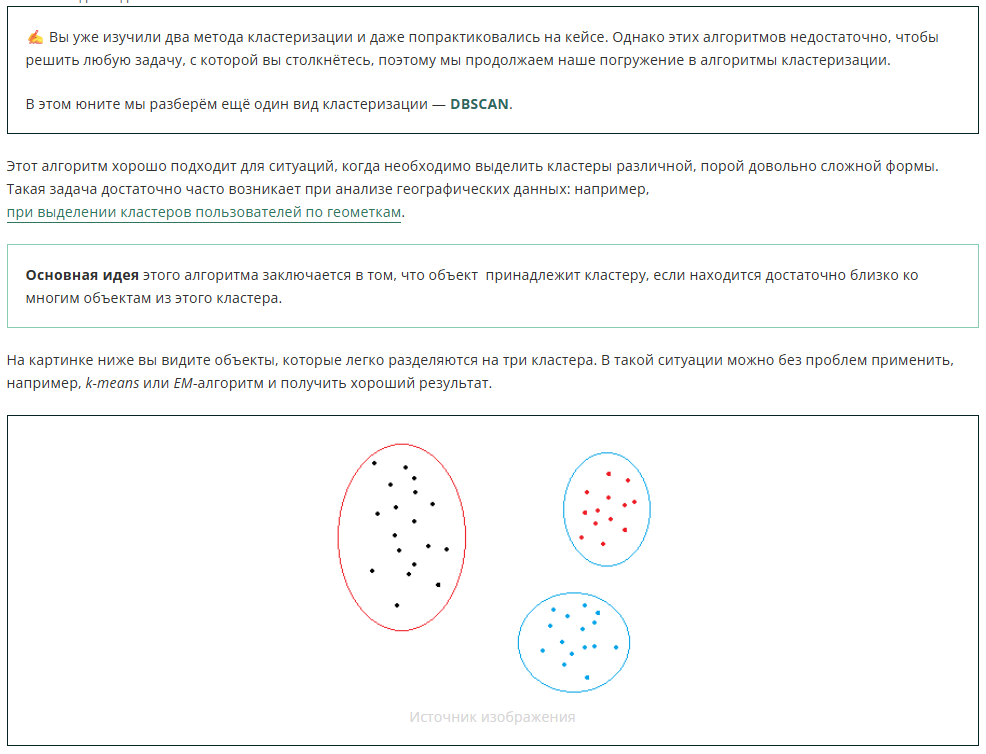

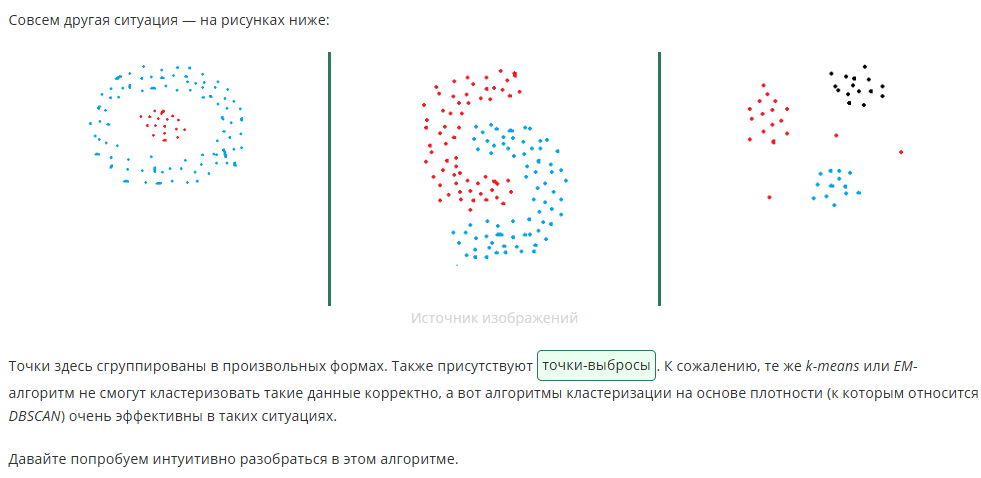

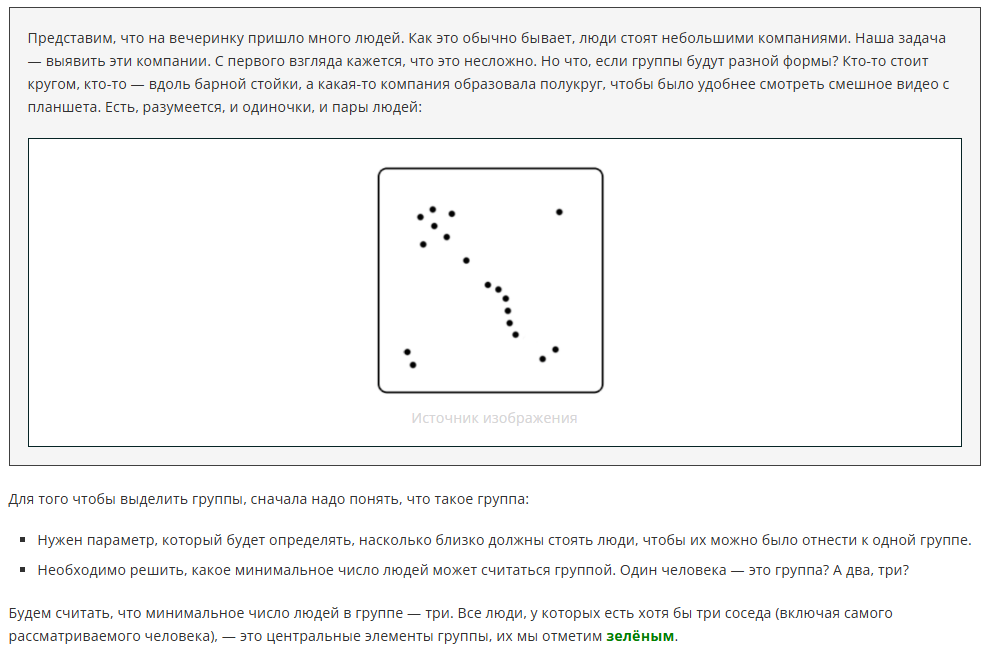

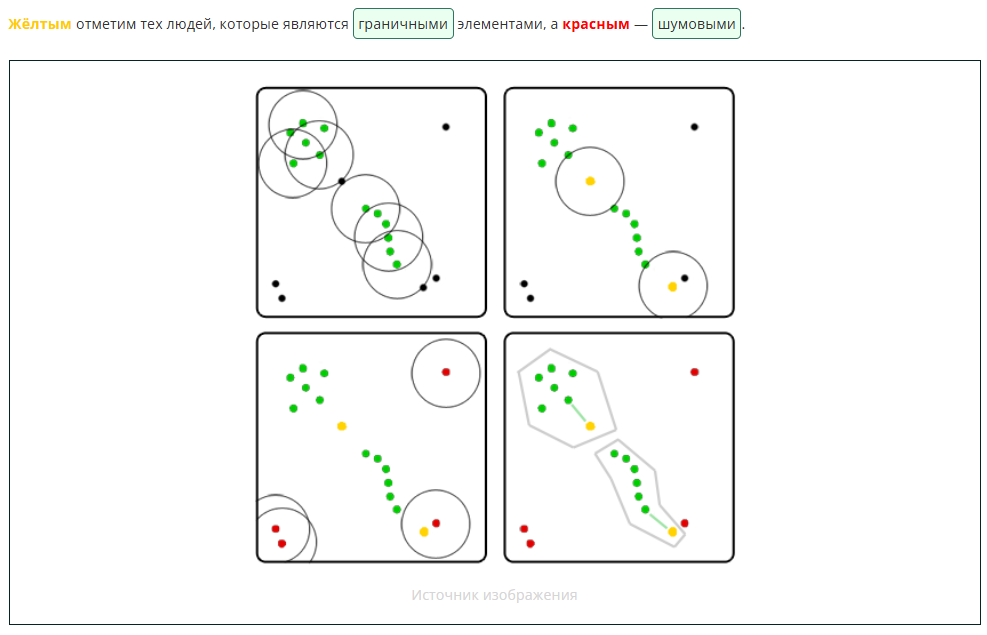

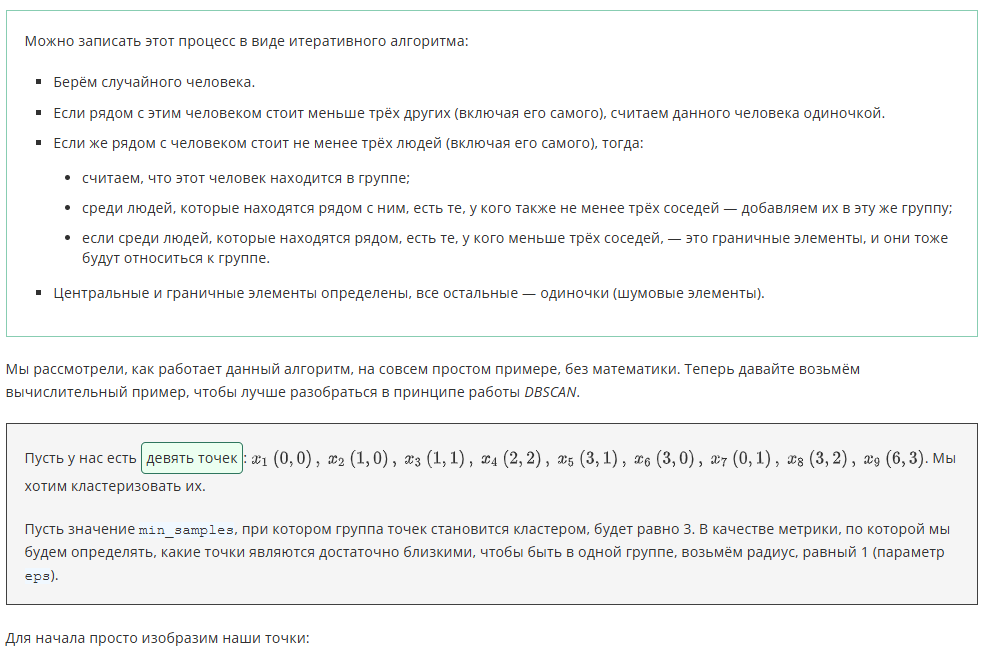

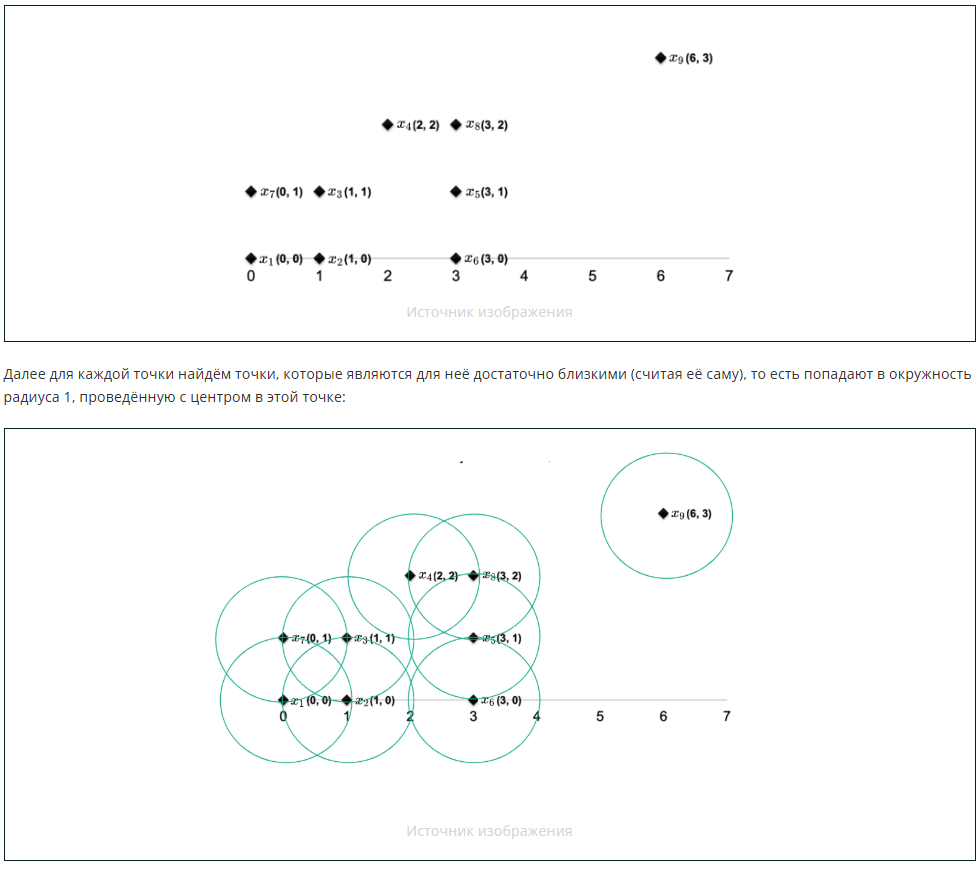

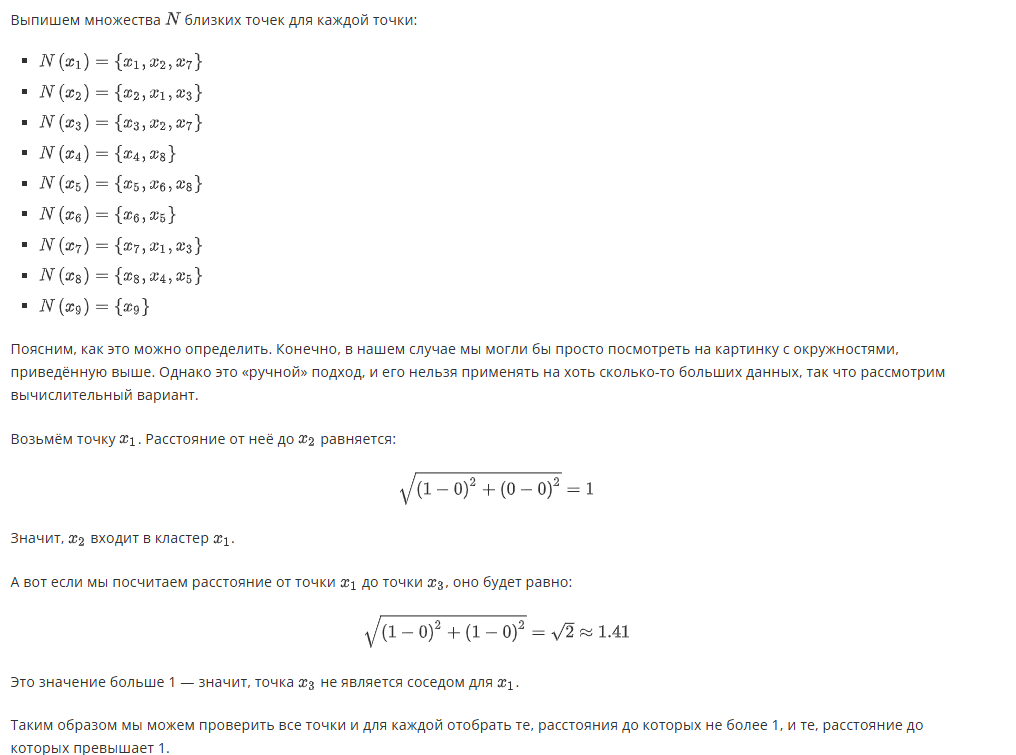

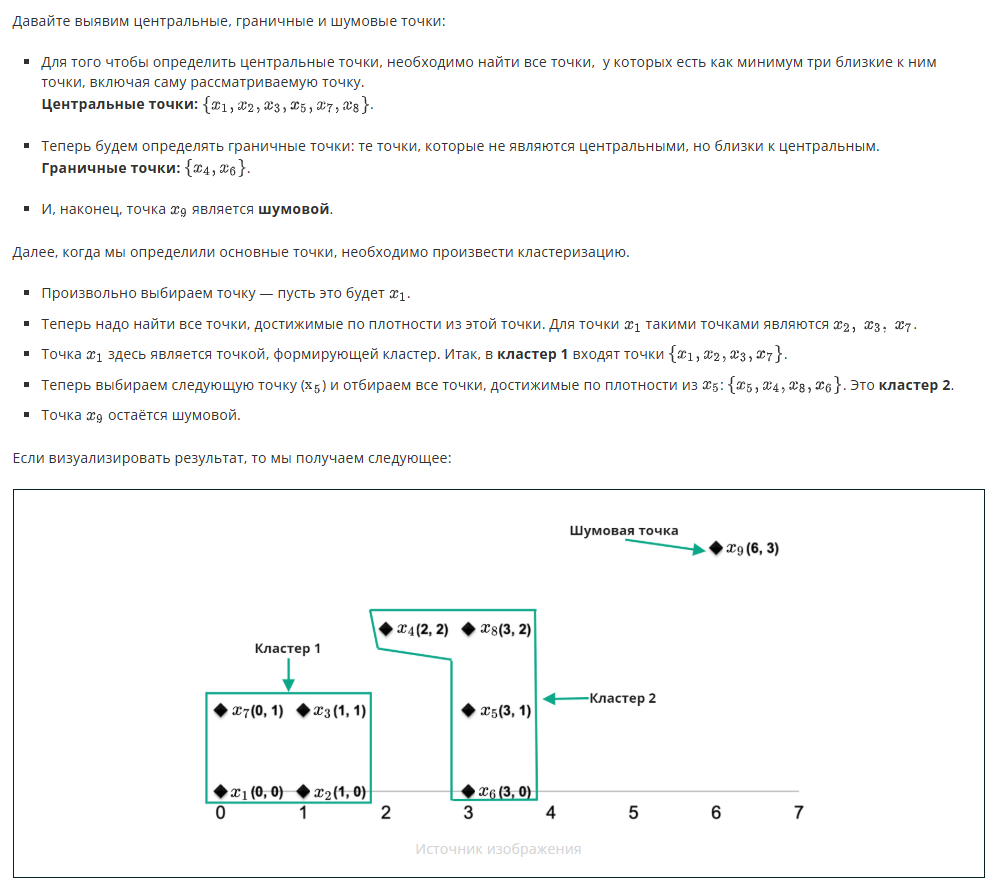

**Алгоритм DBSCAN инициализируется двумя параметрами:**
* ```eps``` — расстояние, определяющее окрестности. Две точки считаются достаточно близкими, чтобы находиться в одном кластере, если расстояние между ними меньше или равно ```eps```. В библиотеке *sklearn* оно по умолчанию равно 0.5.
* ```min_samples``` — минимальное количество точек в данных, которое может быть в кластере. В библиотеке *sklearn* оно по умолчанию равно 5.

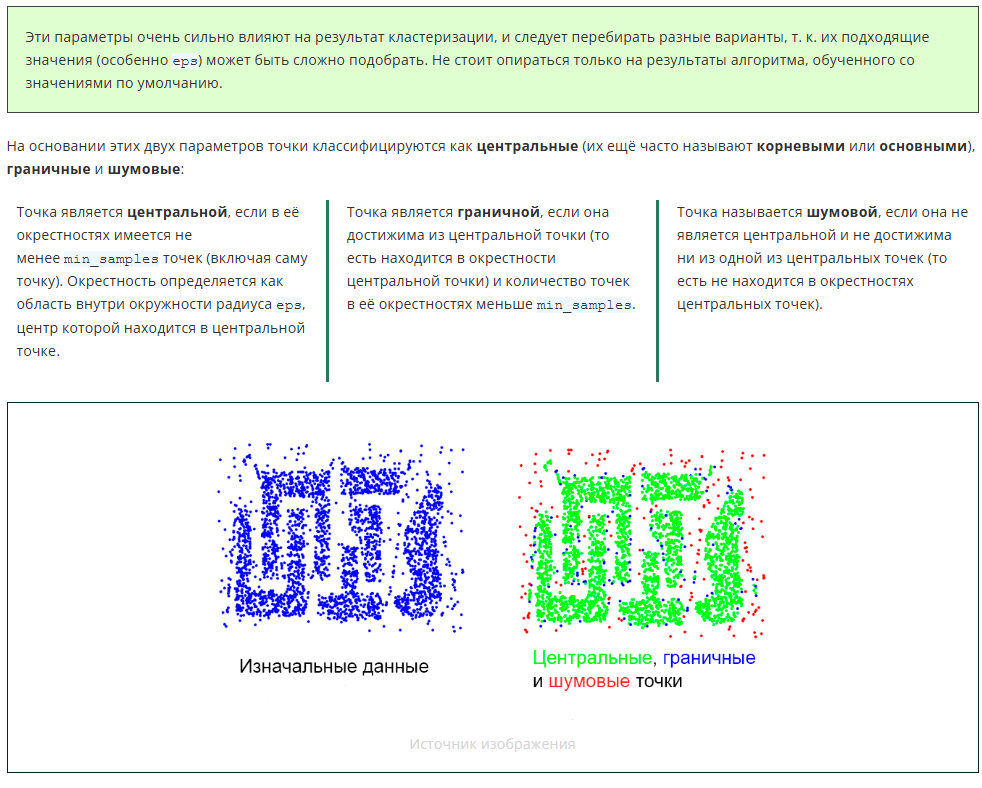

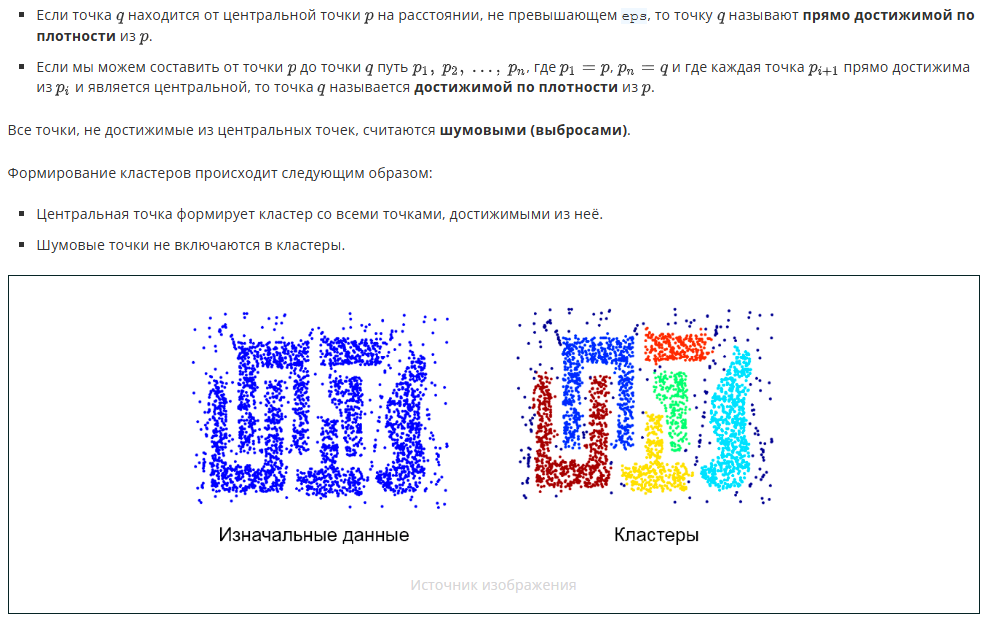

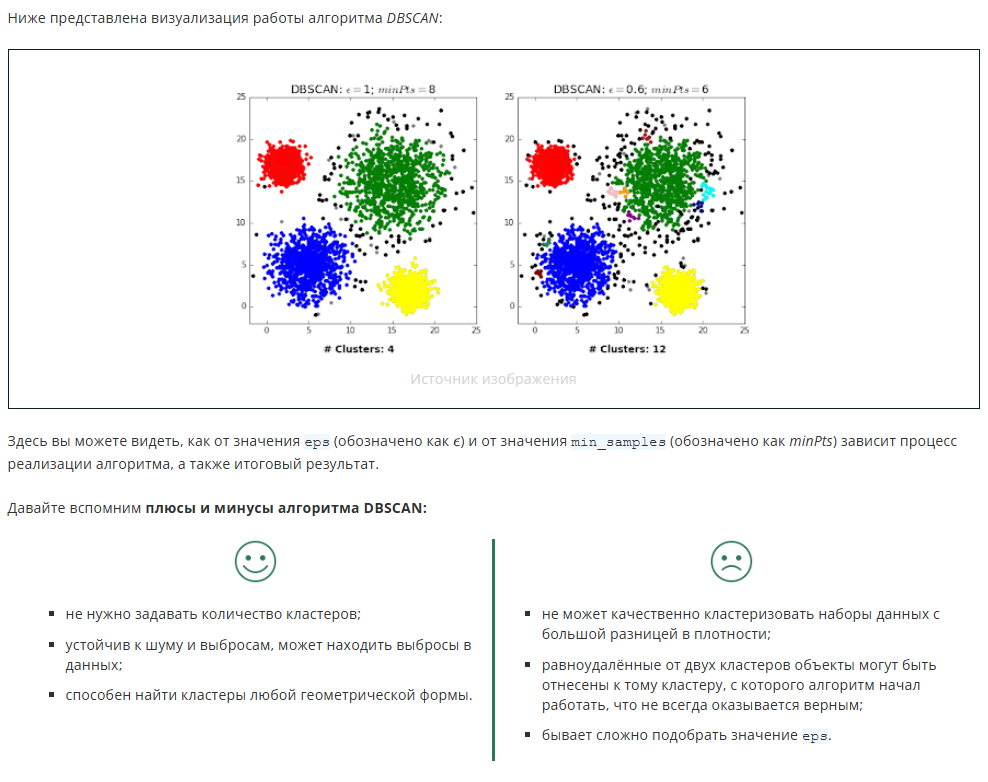

---

# <center>  6. Агломеративная иерархическая кластеризация

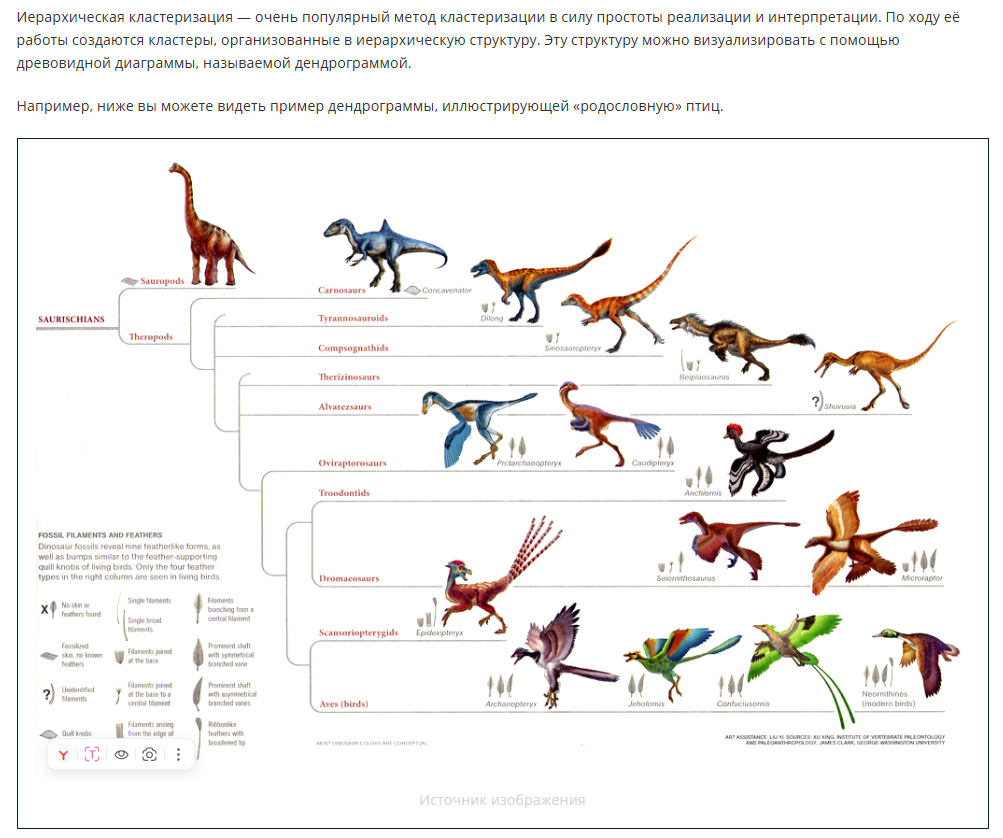

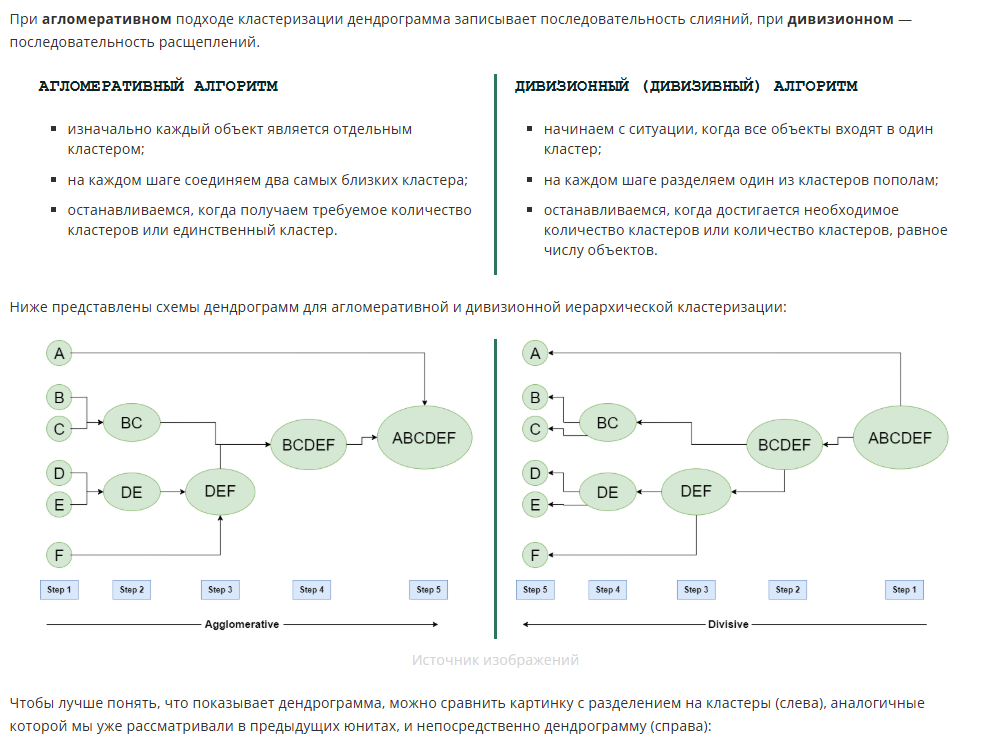

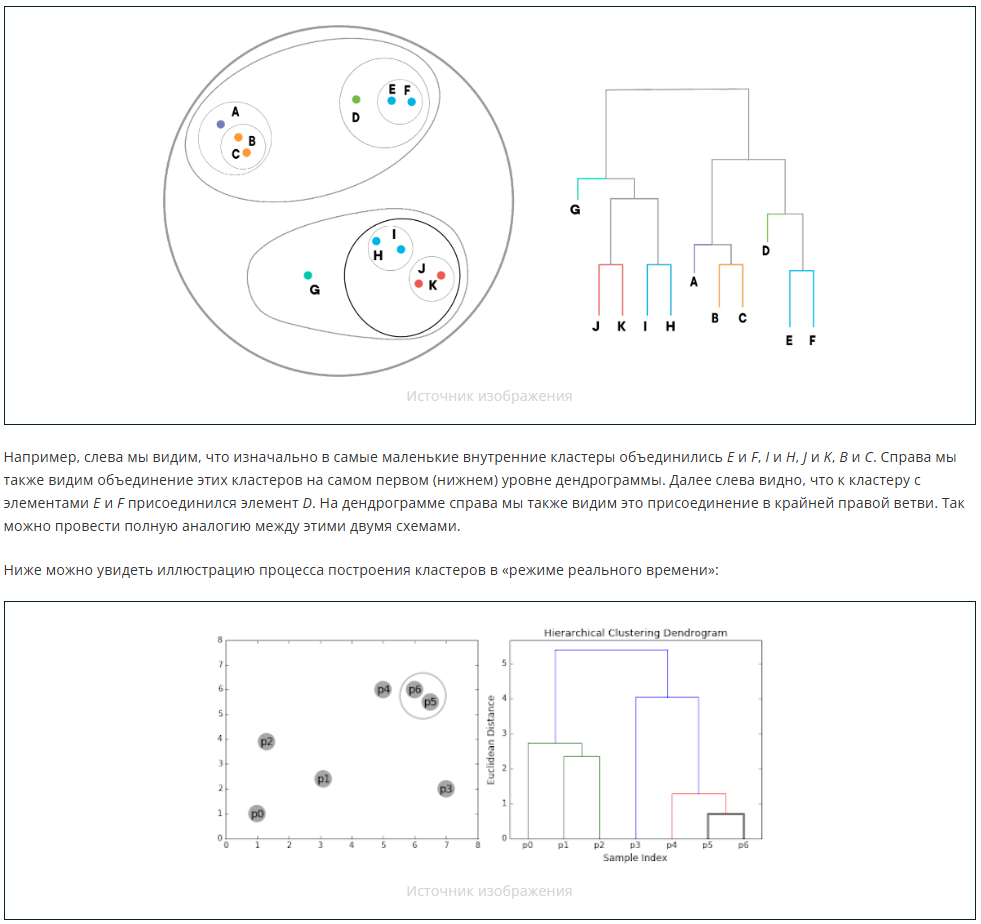

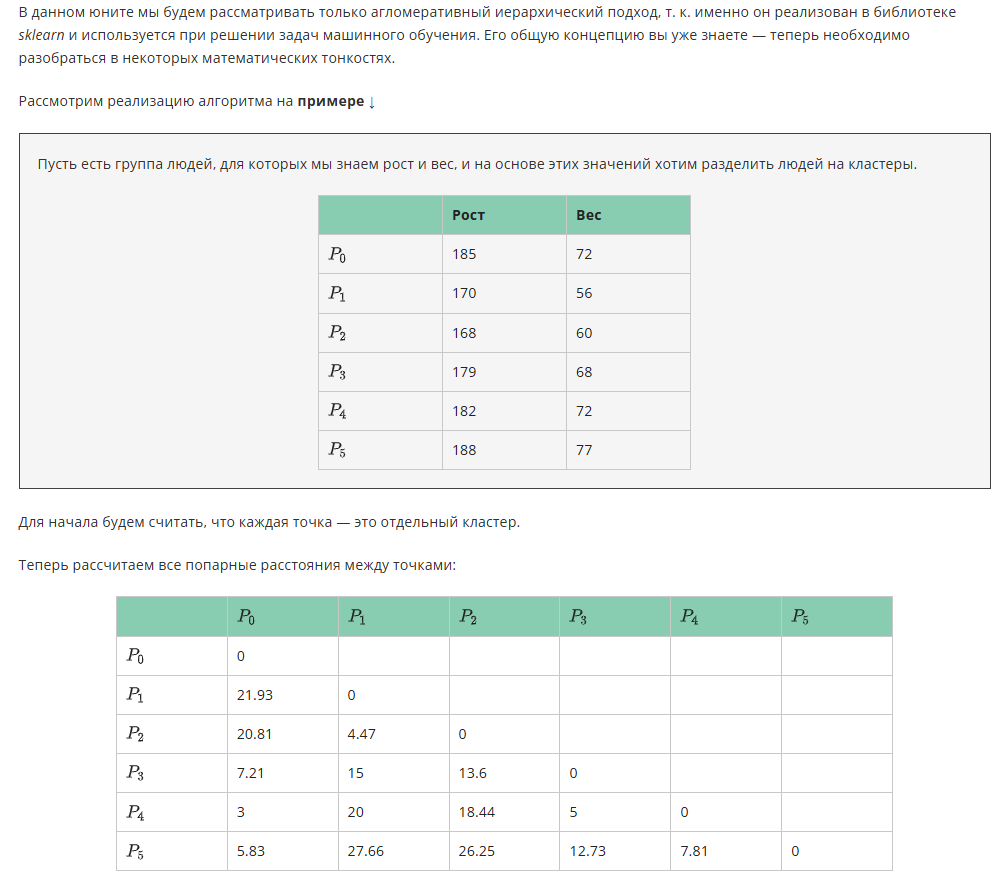

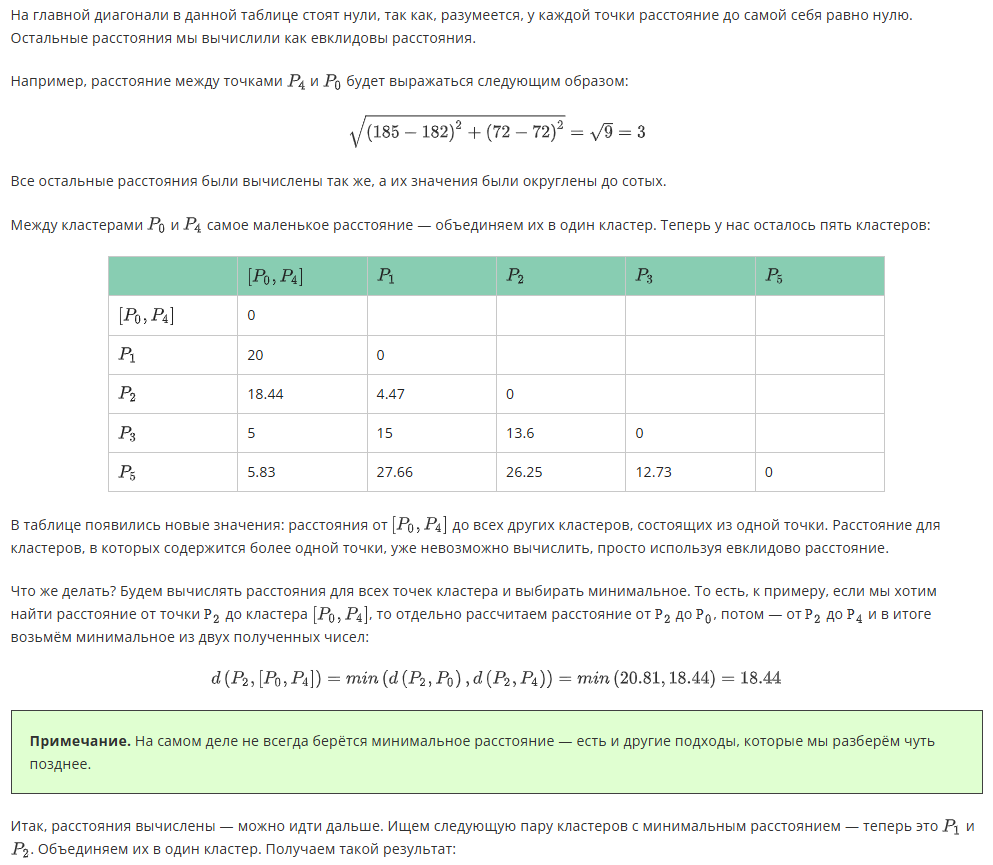

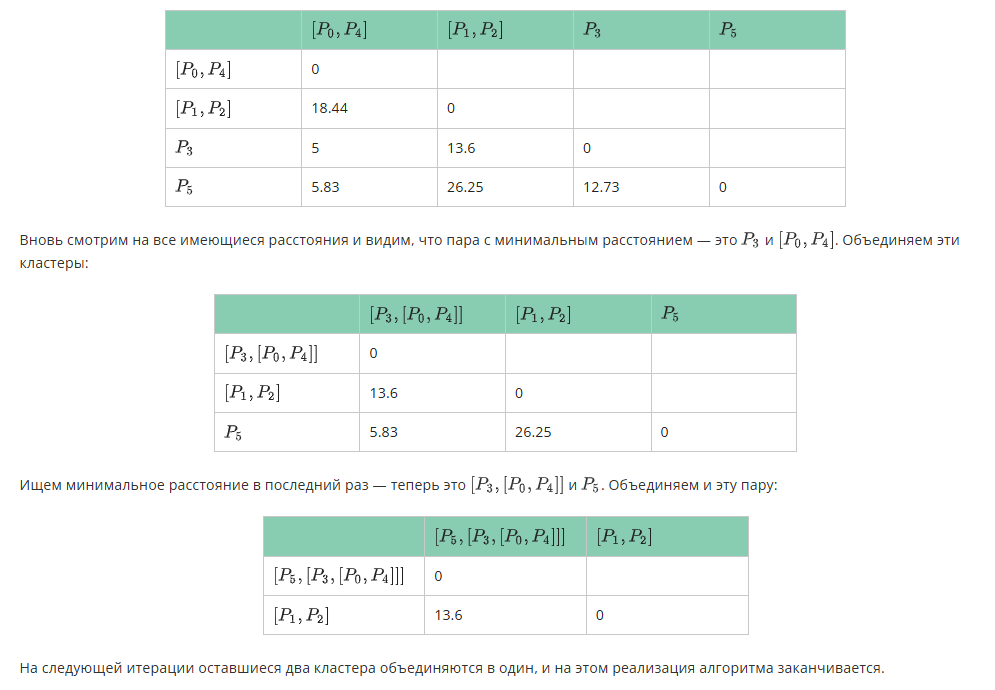

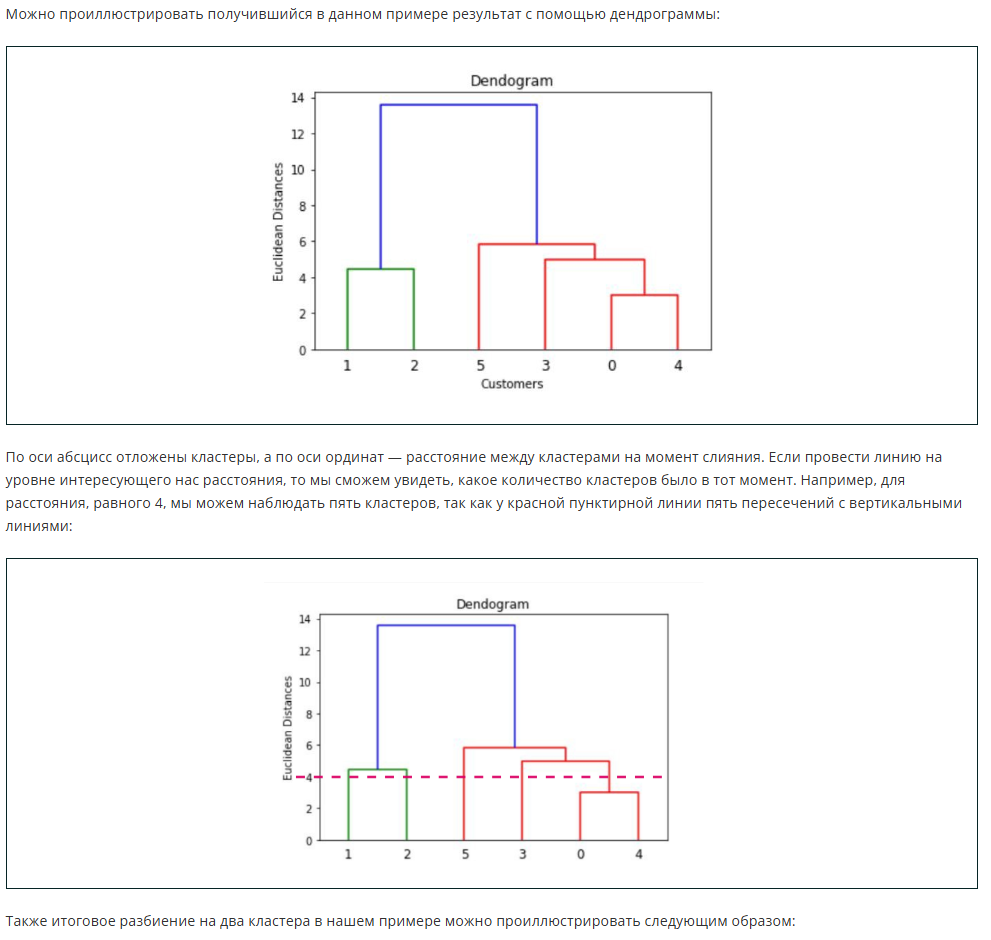

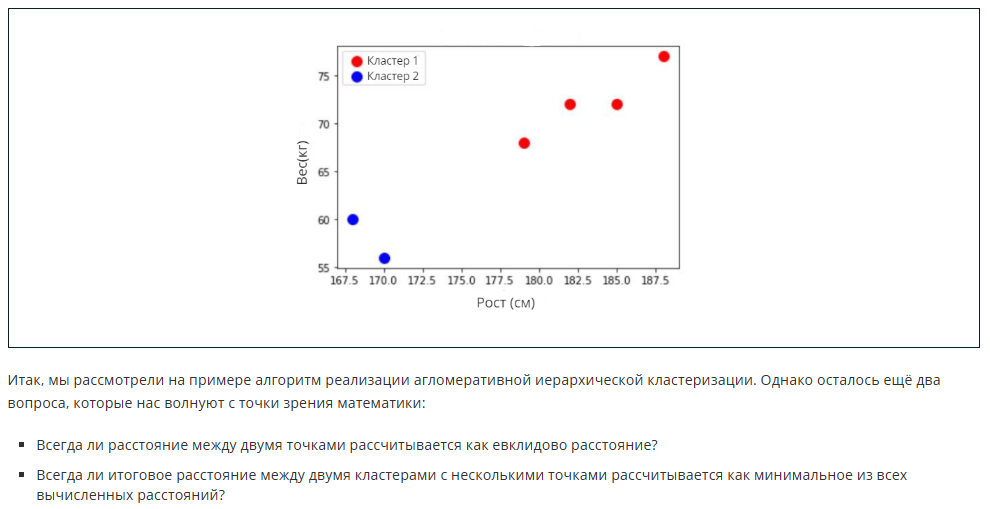

Начнём с первого вопроса. На самом деле, расстояние можно вычислять различными способами. В библиотеке sklearn для вычисления расстояний предлагается несколько вариаций — вот наиболее популярные из них:

**1. Евклидово расстояние:**

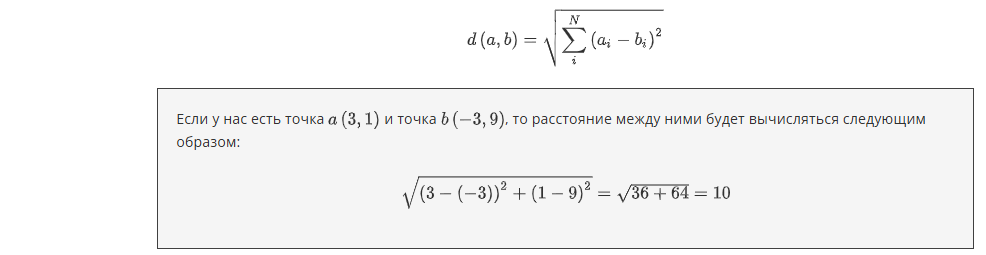

**2. Расстояние городских кварталов (манхэттенское расстояние):**

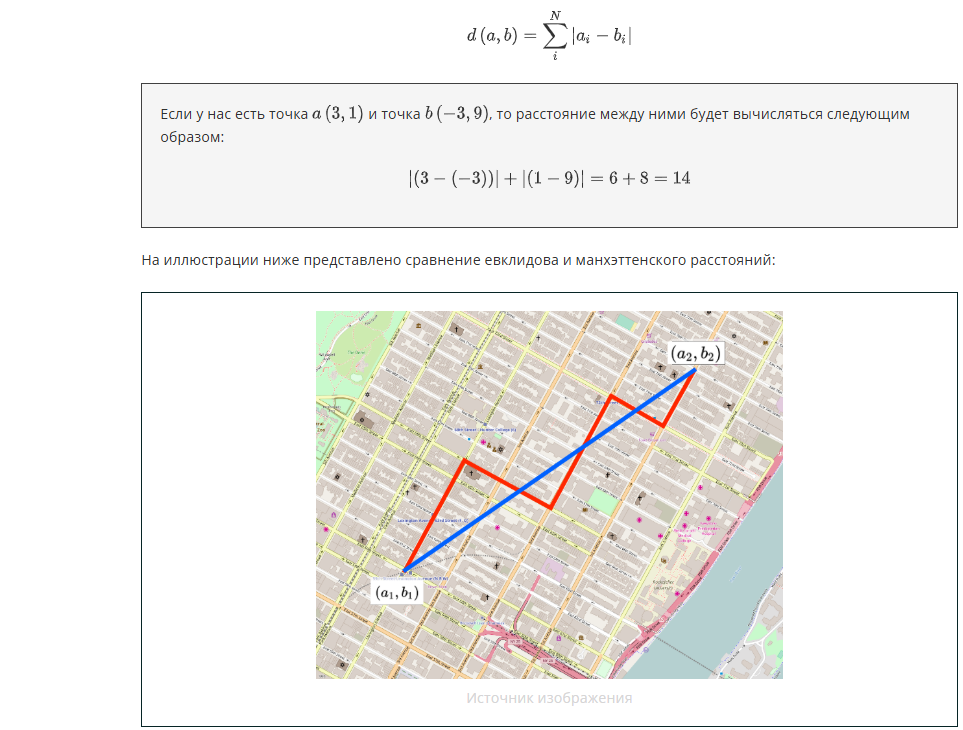

**3. Косинусная мера близости**

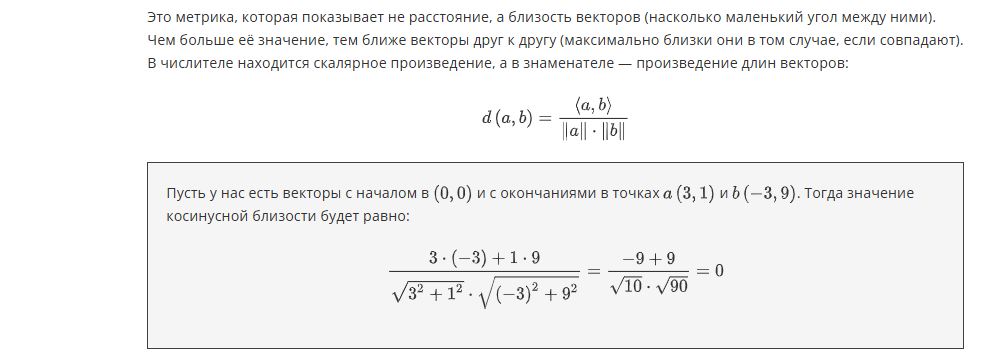

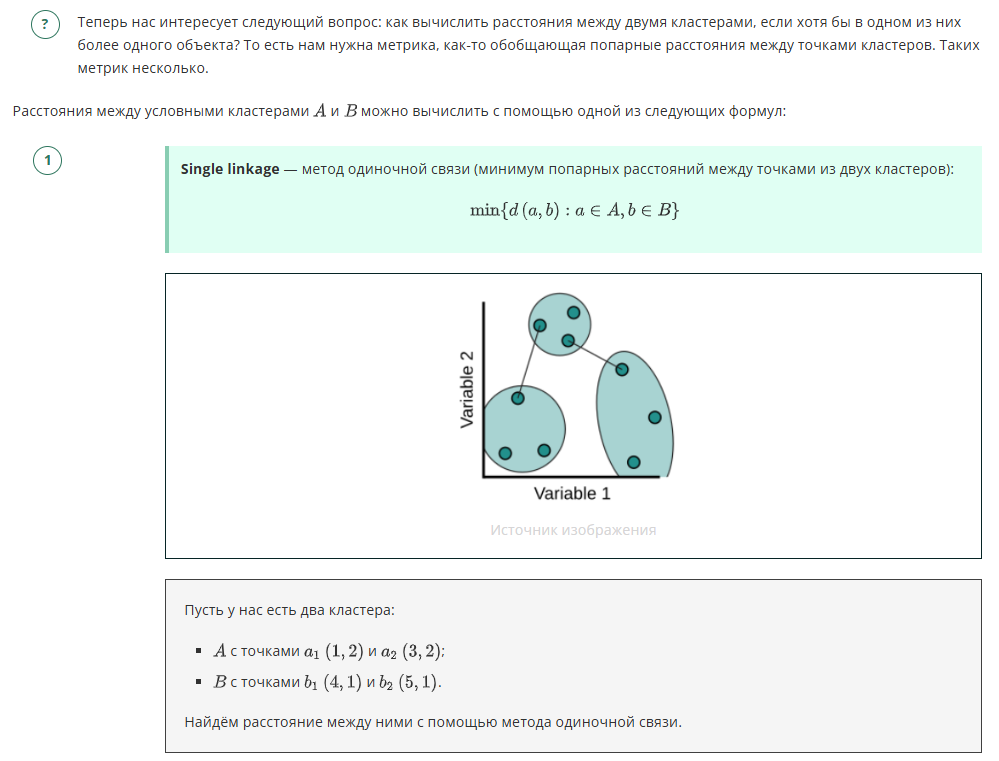

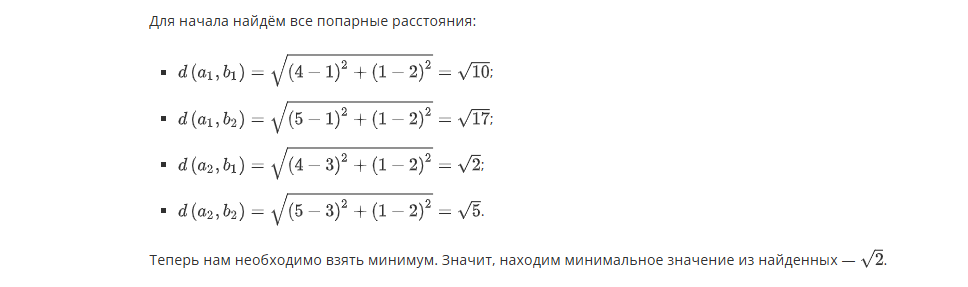

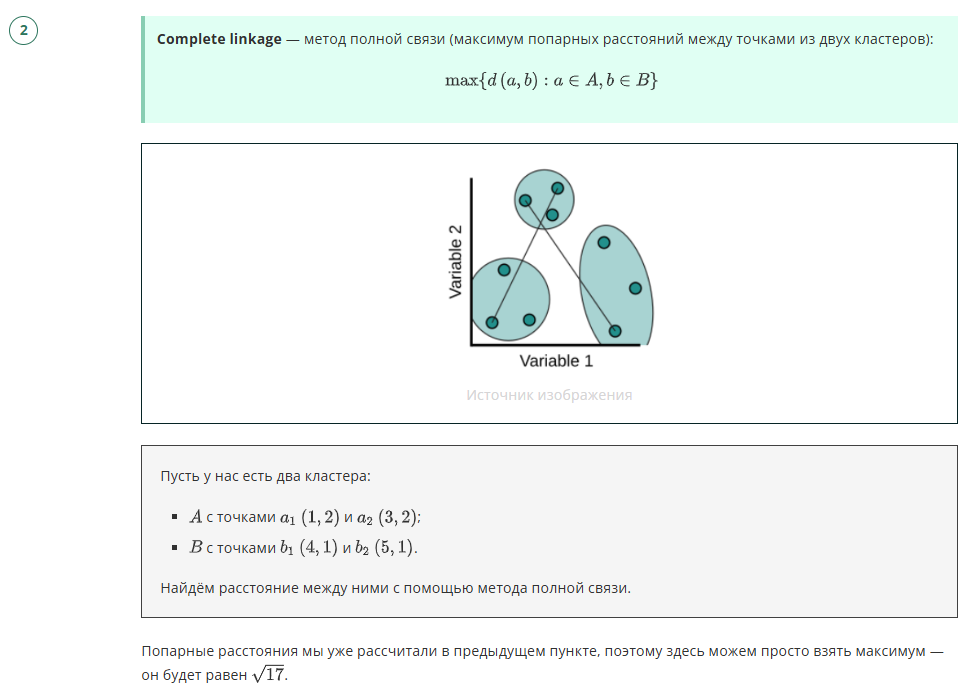

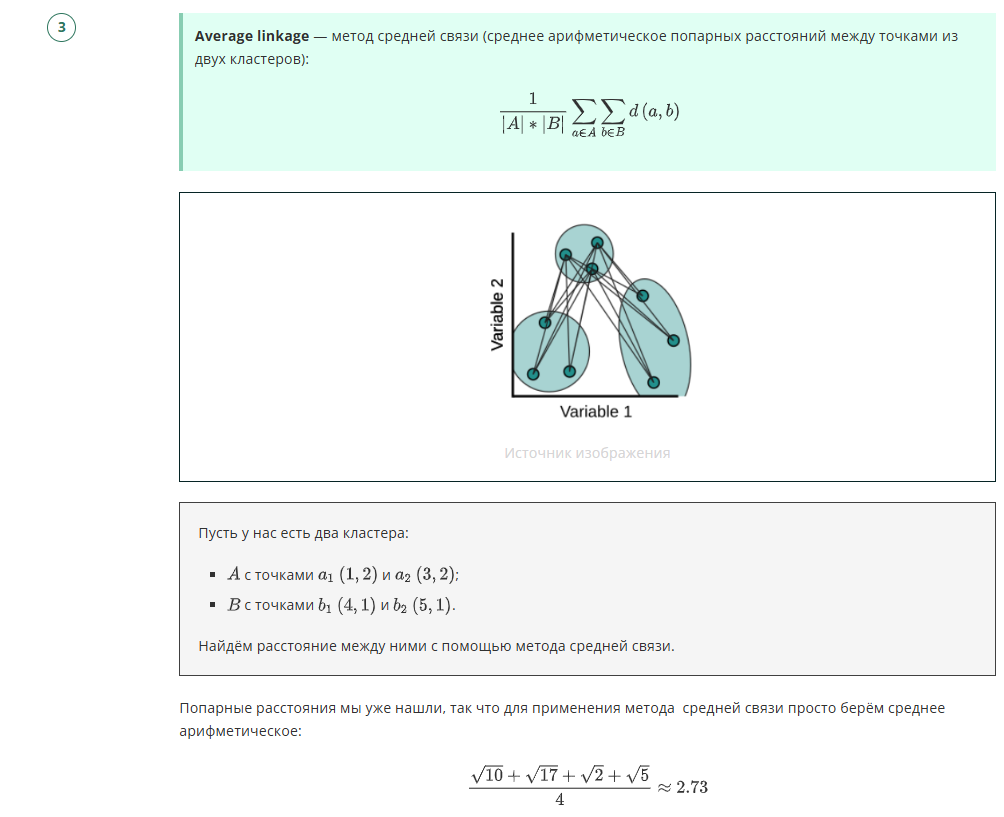

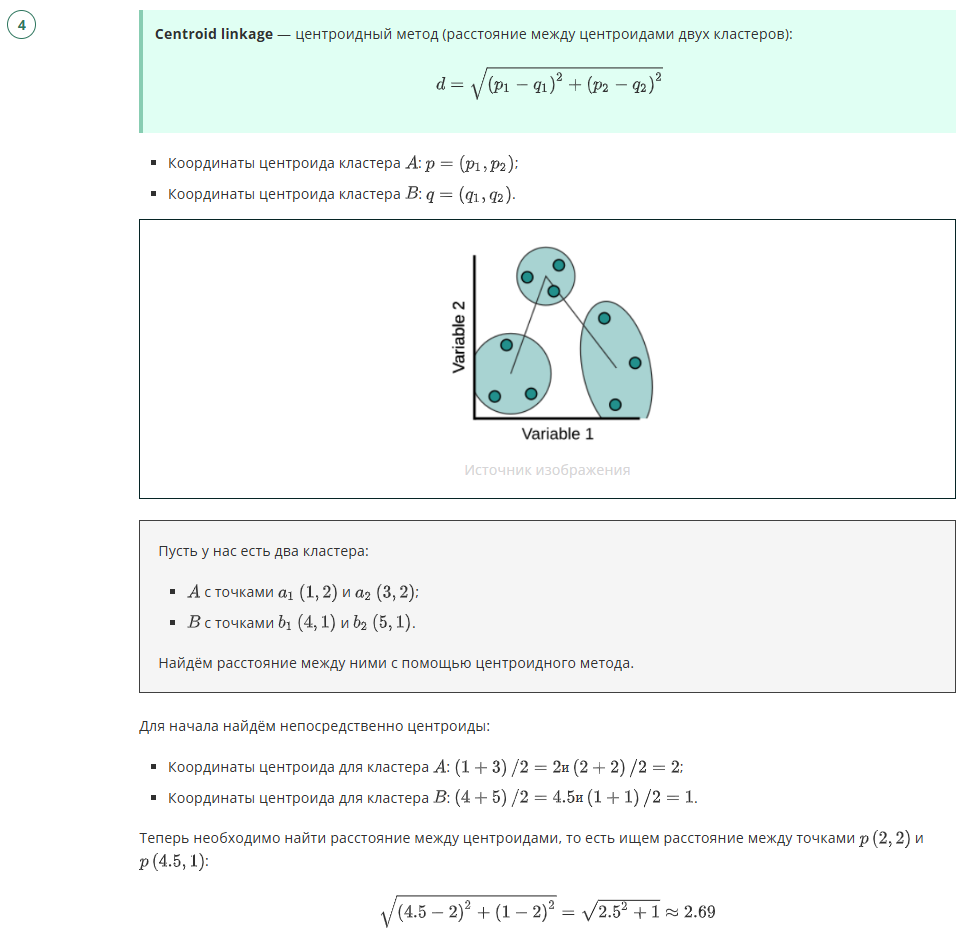

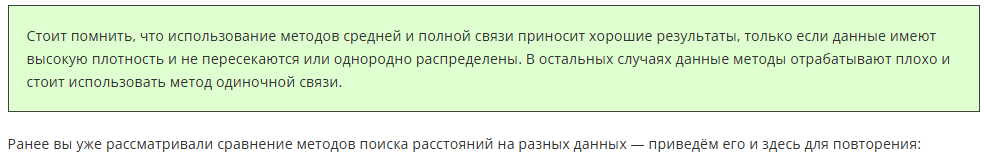

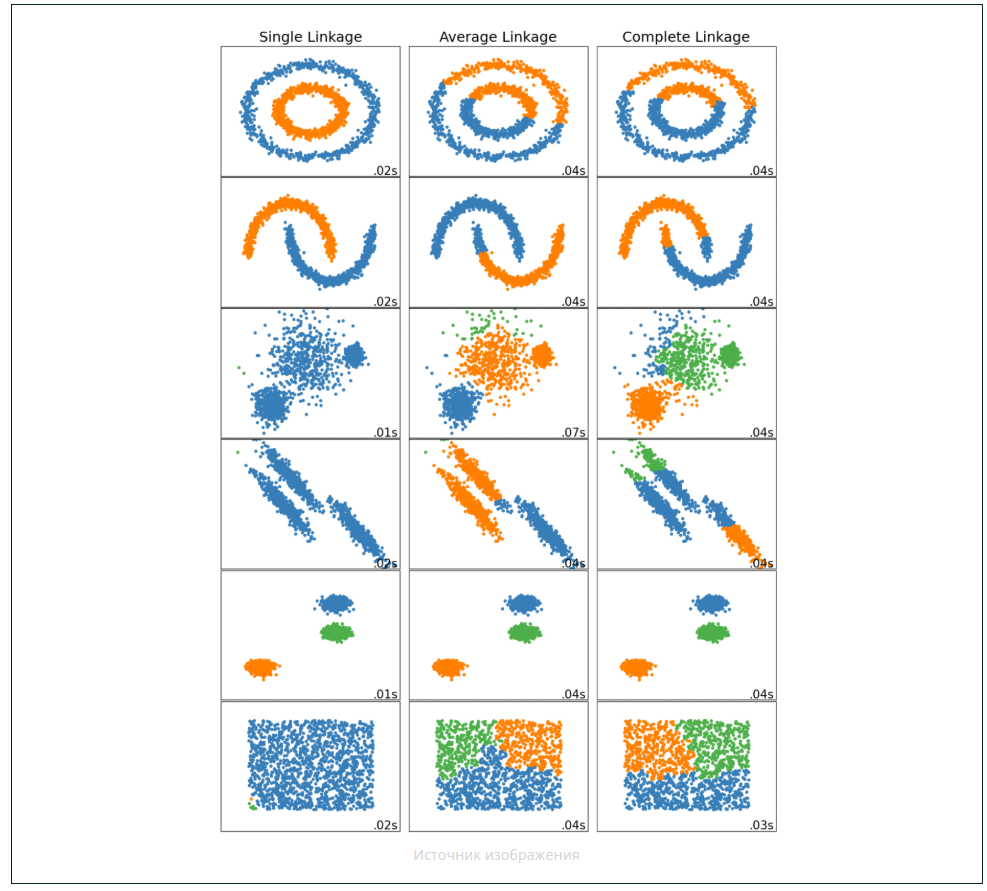

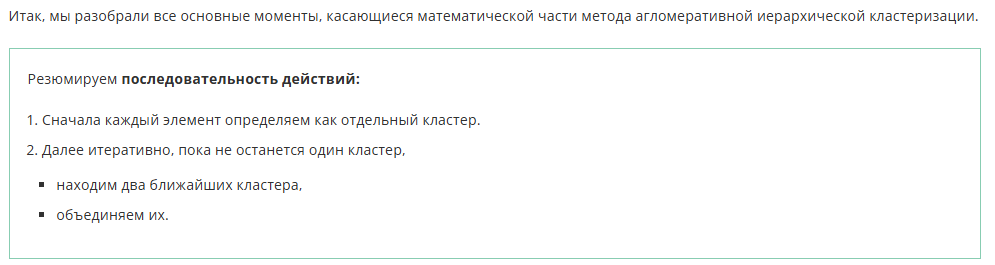

Для реализации алгоритма в sklearn вам понадобится [AgglomerativeClustering](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.AgglomerativeClustering.html). Обычно ему передают следующие параметры:
* ```n_clusters``` — количество кластеров; по умолчанию — 2.
* ```linkage``` — метод определения расстояния между кластерами, которое мы рассматривали выше.
* ```affinity``` — метод определения расстояний между точками (например, евклидово или манхэттенское).

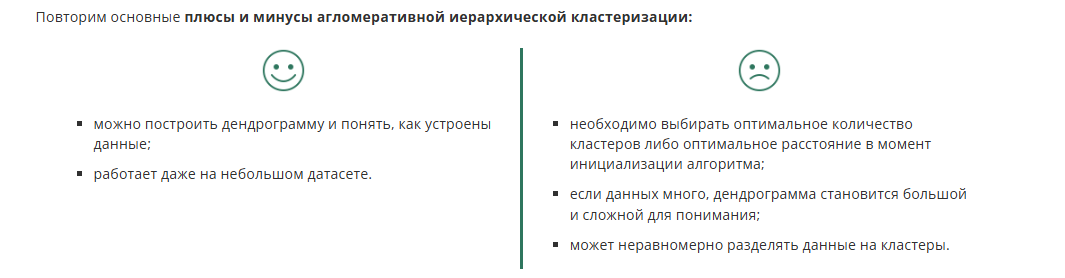

---

# <center> 7. Итоговая практика по алгоритмам кластеризации

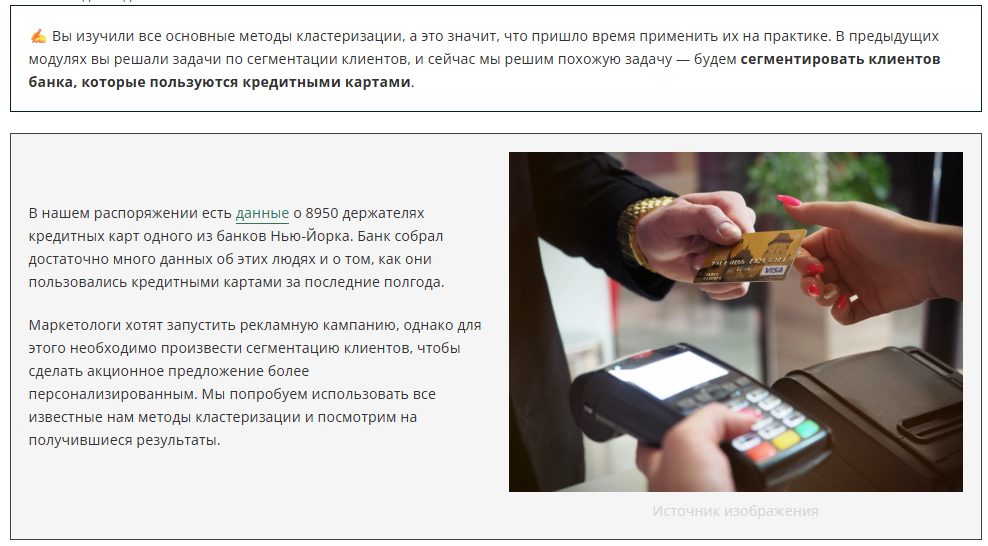

In [22]:
import pandas as pd
df = pd.read_csv('data/CC GENERAL.csv')
df

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.40,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.00,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.00,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.00,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.00,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8945,C19186,28.493517,1.000000,291.12,0.00,291.12,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,325.594462,48.886365,0.500000,6
8946,C19187,19.183215,1.000000,300.00,0.00,300.00,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,275.861322,NaN,0.000000,6
8947,C19188,23.398673,0.833333,144.40,0.00,144.40,0.000000,0.833333,0.000000,0.666667,0.000000,0,5,1000.0,81.270775,82.418369,0.250000,6
8948,C19189,13.457564,0.833333,0.00,0.00,0.00,36.558778,0.000000,0.000000,0.000000,0.166667,2,0,500.0,52.549959,55.755628,0.250000,6


* CUST_ID — идентификационный номер держателя карты;
* BALANCE — баланс, доступный для совершения покупок;
* BALANCEFREQUENCY — как часто обновляется показатель баланса (1 — часто, 0 — нечасто);
* PURCHASES — количество покупок, оплаченных со счёта;
* ONEOFFPURCHASES — максимальная сумма единовременной покупки;
* INSTALLMENTSPURCHASES — сумма покупок, сделанных в рассрочку;
* PURCHASESFREQUENCY — как часто в целом совершаются покупки (1 — часто, 0 — нечасто);
* ONEOFFPURCHASESFREQUENCY — частота совершения единовременных покупок (1 — часто, 0 — нечасто);
* PURCHASESINSTALLMENTSFREQUENCY — частота совершения покупок в рассрочку (1 — часто, 0 — нечасто);
* CASHADVANCEFREQUENCY — частота внесения авансовых платежей;
* CASHADVANCETRX — количество транзакций с авансовыми взносами;
* PURCHASESTRX — количество совершённых транзакций с покупками;
* CREDITLIMIT — кредитный лимит держателя карты;
* PAYMENTS — сумма платежей пользователя;
* MINIMUM_PAYMENTS — сумма минимального платежа пользователя;
* PRCFULLPAYMENT — выплаченный процент от полного платежа;
* TENURE — срок обслуживания кредитной карты.

In [23]:
na = df.isna().sum().sum()
print(f"Пропусков в датасете - {na}")

Пропусков в датасете - 314


In [24]:
numeric_colls = df.select_dtypes(include=['float64','int64'])
for col in numeric_colls:
    mean_val = df[col].mean()
    df[col]=df[col].fillna(mean_val)

In [25]:
print(f"среднее арифметическое для признака MINIMUM_PAYMENTS - {round(df['MINIMUM_PAYMENTS'].mean(),2)}")

среднее арифметическое для признака MINIMUM_PAYMENTS - 864.21


In [26]:
df = df.drop('CUST_ID',axis = 1)
df.head()

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,864.206542,0.000000,12
4,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [28]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_norm = scaler.fit_transform(df)
print(round(X_norm[0][0],2))

-0.73


<Axes: xlabel='cluster', ylabel='silhouette'>

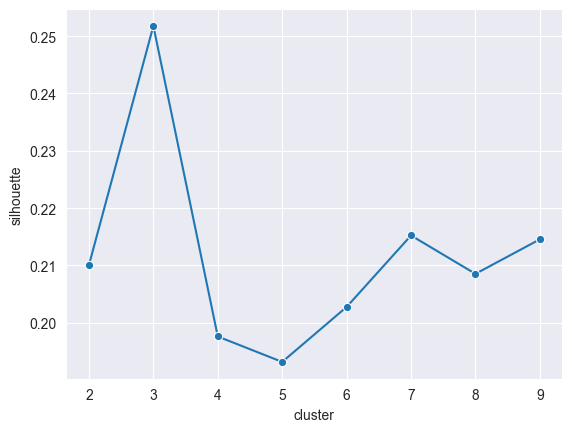

In [29]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
# импортируем метрику силуэта
from sklearn.metrics import silhouette_score
import seaborn as sns
# напишем функцию, как и при подсчете метода локтя
def get_silhouette(cluster_num, X):
    k_means =  KMeans(n_clusters=cluster_num, init='random', n_init=10, random_state=42)
    k_means.fit(X)
# подсчитаем метрику силуэта, передав данные и то, к каким кластерам относятся объекты
    silhouette = silhouette_score(X, k_means.predict(X))
    return silhouette

# создадим пустой словарь, ключами будут инерция и количество кластеров
silhouette_res = {"silhouette": [], "cluster": []}

# выберем нужные данные 
X = X_norm

for cluster_num in range(2, 10):
    silhouette_res["silhouette"].append(get_silhouette(cluster_num, X))
    silhouette_res["cluster"].append(cluster_num)
    
# сохраним в датафрейм значение силуэта и количество кластеров
silhouette_df = pd.DataFrame(silhouette_res)

# установим стиль для визуализиции
sns.set_style("darkgrid")
# визуализируем зависимость значения инерции от количества кластеров
sns.lineplot(data=silhouette_df, x="cluster", y="silhouette", marker= "o")

In [30]:
# 1. Создаём и обучаем модель (именно её сохраняем в переменную)
k_means_model = KMeans(n_clusters=3, random_state=42)
k_means_model.fit(X_norm)

# 2. Теперь можно брать labels_
labels = k_means_model.labels_

import numpy as np
counts = np.bincount(labels)
max_cluster_size = counts.max()
min_cluster_size = counts.min()

print("Размер самого многочисленного кластера:", max_cluster_size)
print("Размер самого малочисленного кластера:", min_cluster_size)

Размер самого многочисленного кластера: 6118
Размер самого малочисленного кластера: 1235


c:\Users\PC\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


In [31]:
from sklearn.cluster import DBSCAN
dbscan_model =DBSCAN()
dbscan_model.fit(X_norm)
# 2. Теперь можно брать labels_
labels = dbscan_model.labels_
# 2. Считаем количество КЛАСТЕРОВ (исключая шум)
unique_labels = set(labels)
n_clusters = len([l for l in unique_labels if l != -1])

print("Уникальные метки (включая шум -1):", unique_labels)
print("Количество выделенных кластеров (без шума):", n_clusters)

Уникальные метки (включая шум -1): {0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, -1}
Количество выделенных кластеров (без шума): 38


In [32]:
# Диапазон параметров
eps_values = np.arange(2, 6, 0.2)      # от 0.1 до 2.9 с шагом 0.2
min_samples_values = range(1, 20, 4)    # 1, 5, 9, 13, 17

best_score = -1                 # silhouette лежит в [-1, 1], начинаем с заведомо плохого
best_params = None
best_labels = None

print("Начинаем перебор параметров...")

for eps in eps_values:
    for min_samples in min_samples_values:
        # Инициализируем и обучаем DBSCAN
        db = DBSCAN(eps=eps, min_samples=min_samples)
        labels = db.fit_predict(X_norm)   # fit_predict сразу возвращает метки
        
        # DBSCAN может пометить все точки как шум (-1). Тогда silhouette_score не посчитается.
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        
        if n_clusters < 2:
            # silhouette требует хотя бы 2 кластера
            continue
        
        # Считаем коэффициент силуэта
        score = silhouette_score(X_norm, labels)
        
        # Обновляем лучший результат
        if score > best_score:
            best_score = score
            best_params = (eps, min_samples)
            best_labels = labels
            print(f"Новый лучший: eps={eps}, min_samples={min_samples}, silhouette={score:.2f}")

print("\nЛучший результат:")
print(f"eps = {best_params[0]}, min_samples = {best_params[1]}")
print(f"Silhouette score = {best_score:.2f}")

Начинаем перебор параметров...
Новый лучший: eps=2.0, min_samples=1, silhouette=-0.23
Новый лучший: eps=2.0, min_samples=5, silhouette=0.40
Новый лучший: eps=4.200000000000002, min_samples=1, silhouette=0.41
Новый лучший: eps=4.400000000000002, min_samples=1, silhouette=0.41
Новый лучший: eps=4.600000000000002, min_samples=1, silhouette=0.45
Новый лучший: eps=4.600000000000002, min_samples=5, silhouette=0.71
Новый лучший: eps=4.8000000000000025, min_samples=5, silhouette=0.71
Новый лучший: eps=5.000000000000003, min_samples=5, silhouette=0.71
Новый лучший: eps=5.200000000000003, min_samples=5, silhouette=0.71
Новый лучший: eps=5.800000000000003, min_samples=5, silhouette=0.75

Лучший результат:
eps = 5.800000000000003, min_samples = 5
Silhouette score = 0.75


In [ ]:

from sklearn.metrics import pairwise_distances

# Считаем попарные расстояния между первыми 100 точками
dists = pairwise_distances(X_norm[:100])
print("Минимум:", dists.min())
print("Медиана:", np.median(dists))
print("95‑й перцентиль:", np.percentile(dists, 95))

Минимум: 0.0
Медиана: 4.536057639832379
95‑й перцентиль: 9.17961774263272


In [ ]:
import numpy as np
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Диапазон количества кластеров: от 3 до 9 включительно
n_clusters_range = range(3, 10)

best_score = -1
best_n_clusters = None
best_labels = None

print("Начинаем перебор числа кластеров...")

for n_clusters in n_clusters_range:
    # Создаём модель: linkage='ward' — хороший дефолт для таких задач
    model = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward')
    
    # fit_predict сразу обучает и возвращает метки кластеров
    labels = model.fit_predict(X_norm)
    
    # Считаем silhouette score: чем ближе к 1 — тем лучше
    score = silhouette_score(X_norm, labels)
    
    print(f"n_clusters={n_clusters}, silhouette={score:.2f}")
    
    if score > best_score:
        best_score = score
        best_n_clusters = n_clusters
        best_labels = labels

print("\nЛучший результат:")
print(f"Оптимальное число кластеров: {best_n_clusters}")
print(f"Silhouette score: {best_score:.2f}")

Начинаем перебор числа кластеров...
n_clusters=3, silhouette=0.17
n_clusters=4, silhouette=0.15
n_clusters=5, silhouette=0.16
n_clusters=6, silhouette=0.17
n_clusters=7, silhouette=0.16
n_clusters=8, silhouette=0.15
n_clusters=9, silhouette=0.15

Лучший результат:
Оптимальное число кластеров: 6
Silhouette score: 0.17


In [ ]:
model = AgglomerativeClustering(n_clusters=6, linkage='ward')
model.fit(X_norm)

# 2. Теперь можно брать labels_
labels = model.labels_

import numpy as np
counts = np.bincount(labels)
max_cluster_size = counts.max()
min_cluster_size = counts.min()

print("Размер самого многочисленного кластера:", max_cluster_size)
print("Размер самого малочисленного кластера:", min_cluster_size)

Размер самого многочисленного кластера: 3946
Размер самого малочисленного кластера: 23


c:\Users\PC\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


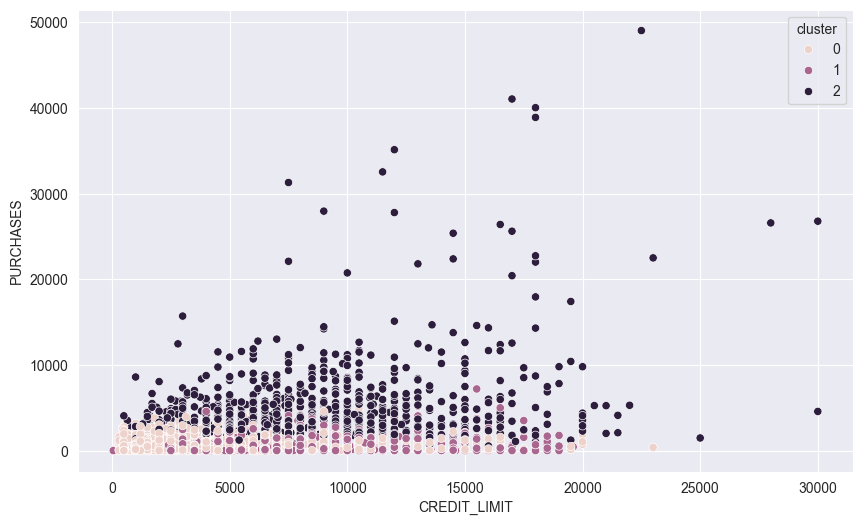

In [33]:
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(X_norm)
df['cluster'] = kmeans.labels_
plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='CREDIT_LIMIT', y='PURCHASES', hue='cluster')
plt.show()